# Linear Regression Project
## Market Campaign Sales Prediction Project

## 1. Import Necessary Library


In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## 2. Import Dataset

In [13]:
market_df=pd.read_csv("C:/Users/DELL/OneDrive/Desktop/Python project/Linear Regression project -Market Campaign Sales Prediction Project/market_sales - LMS dataset.csv")
market_df

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate,Sales
0,22483.0,17282.0,30.0,10516,Electronics,East,Budget,1000,2.11,96119
1,19308.0,18872.0,5.0,10413,Home Appliances,North,Budget,1000,2.15,82430
2,23238.0,13674.0,15.0,5715,Home Appliances,East,Mid-tier,1000,3.50,115771
3,27615.0,12551.0,20.0,10844,FMCG,South,Mid-tier,1825,2.14,83833
4,18829.0,10659.0,15.0,14564,Sports,East,Mid-tier,1000,2.55,103896
...,...,...,...,...,...,...,...,...,...,...
2495,24066.0,14804.0,0.0,10249,Fashion,West,Premium,1000,2.41,82724
2496,18605.0,17845.0,30.0,10193,Electronics,North,Premium,1038,2.47,99914
2497,18601.0,27451.0,0.0,19435,NaN,South,Premium,1053,2.19,110831
2498,23951.0,18232.0,NaN,2291,Electronics,West,Mid-tier,1000,1.50,58640


## 3. Exploratory Data Analysis

In [14]:
# head
market_df.head()

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate,Sales
0,22483.0,17282.0,30.0,10516,Electronics,East,Budget,1000,2.11,96119
1,19308.0,18872.0,5.0,10413,Home Appliances,North,Budget,1000,2.15,82430
2,23238.0,13674.0,15.0,5715,Home Appliances,East,Mid-tier,1000,3.50,115771
3,27615.0,12551.0,20.0,10844,FMCG,South,Mid-tier,1825,2.14,83833
4,18829.0,10659.0,15.0,14564,Sports,East,Mid-tier,1000,2.55,103896


In [15]:
# shape
market_df.shape

(2500, 10)

In [16]:
# info
market_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   TV_Ad_Spend                    2405 non-null   float64
 1   Social_Media_Spend             2344 non-null   float64
 2   Discount_Offers                2318 non-null   float64
 3   Search_Engine_Marketing_Spend  2500 non-null   int64  
 4   Product_Category               2333 non-null   str    
 5   Region                         2373 non-null   str    
 6   Customer_Segment               2500 non-null   str    
 7   Website_Traffic                2500 non-null   int64  
 8   Conversion_Rate                2500 non-null   float64
 9   Sales                          2500 non-null   int64  
dtypes: float64(4), int64(3), str(3)
memory usage: 243.0 KB


In [17]:
# describe
market_df.describe()

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Website_Traffic,Conversion_Rate,Sales
count,2405.000000,2344.000000,2318.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,20154.879834,14921.009812,14.309750,11900.040400,1175.940000,2.136004,83898.009200
std,4893.791754,4038.474895,8.885829,3577.258013,282.022437,0.645222,27916.528551
min,5000.000000,3000.000000,0.000000,2000.000000,1000.000000,0.500000,18747.000000
25%,16884.000000,12215.750000,10.000000,9479.750000,1000.000000,1.670000,63358.750000
50%,20126.000000,15007.500000,15.000000,11856.500000,1000.000000,2.090000,81320.500000
75%,23362.000000,17555.750000,20.000000,14394.250000,1279.000000,2.540000,101064.000000
max,39263.000000,30000.000000,30.000000,24351.000000,2542.000000,4.750000,221038.000000


In [18]:
# Missing Values
market_df.isna().sum()

TV_Ad_Spend                       95
Social_Media_Spend               156
Discount_Offers                  182
Search_Engine_Marketing_Spend      0
Product_Category                 167
Region                           127
Customer_Segment                   0
Website_Traffic                    0
Conversion_Rate                    0
Sales                              0
dtype: int64

In [19]:
# Percentage of columns
market_df.isna().sum()/len(market_df)*100

TV_Ad_Spend                      3.80
Social_Media_Spend               6.24
Discount_Offers                  7.28
Search_Engine_Marketing_Spend    0.00
Product_Category                 6.68
Region                           5.08
Customer_Segment                 0.00
Website_Traffic                  0.00
Conversion_Rate                  0.00
Sales                            0.00
dtype: float64

In [20]:
# Duplicates
market_df.duplicated().sum()

np.int64(0)

In [21]:
# Outliers (we have 2 method(z_score/IQR))
# Using IQR method

number_cols=market_df.select_dtypes(include='number').columns

for col in number_cols:
    Min=market_df[col].min()
    Q1=market_df[col].quantile(0.25)
    Q2=market_df[col].quantile(0.50)
    Mean=market_df[col].mean()
    Q3=market_df[col].quantile(0.75)
    Max=market_df[col].max()

    IQR=Q3-Q1

    lower_out_value= Q1-1.5*IQR
    upper_out_value= Q3+1.5*IQR


    Lower_Outliers=(market_df[col] < lower_out_value).sum()
    Upper_Outliers=(market_df[col] > upper_out_value).sum()
    total_outliers=Lower_Outliers+Upper_Outliers

    print(f'Columns is {col}')
    print('_'*50)
    print(f'Minimum value of {col} is {Min}')
    print(f'Quartile 1 of {col} is {Q1}')
    print(f'Median value of {col} is {Q2}')
    print(f'Average value of {col} is {Mean}')
    print(f'Quartile 3 of {col} is {Q3}')
    print(f'Maximum value of {col} is {Max}')
    print(f'Lower Outliers value of {col} is {lower_out_value}')
    print(f'Upper Outliers value of {col} is {upper_out_value}')
    print(f'Lower Outliers count is {Lower_Outliers}')
    print(f'Upper Outliers count is {Upper_Outliers}')
    print(f'Total Outliers count is {total_outliers}')
    print('='*80)
    print(' ')
    


    
    

Columns is TV_Ad_Spend
__________________________________________________
Minimum value of TV_Ad_Spend is 5000.0
Quartile 1 of TV_Ad_Spend is 16884.0
Median value of TV_Ad_Spend is 20126.0
Average value of TV_Ad_Spend is 20154.879833679835
Quartile 3 of TV_Ad_Spend is 23362.0
Maximum value of TV_Ad_Spend is 39263.0
Lower Outliers value of TV_Ad_Spend is 7167.0
Upper Outliers value of TV_Ad_Spend is 33079.0
Lower Outliers count is 13
Upper Outliers count is 9
Total Outliers count is 22
 
Columns is Social_Media_Spend
__________________________________________________
Minimum value of Social_Media_Spend is 3000.0
Quartile 1 of Social_Media_Spend is 12215.75
Median value of Social_Media_Spend is 15007.5
Average value of Social_Media_Spend is 14921.00981228669
Quartile 3 of Social_Media_Spend is 17555.75
Maximum value of Social_Media_Spend is 30000.0
Lower Outliers value of Social_Media_Spend is 4205.75
Upper Outliers value of Social_Media_Spend is 25565.75
Lower Outliers count is 13
Upper

Columns is TV_Ad_Spend
__________________________________________________
Minimum value of TV_Ad_Spend is 5000.0
Quartile 1 of TV_Ad_Spend is 16884.0
Median value of TV_Ad_Spend is 20126.0
Average value of TV_Ad_Spend is 20154.879833679835
Quartile 3 of TV_Ad_Spend is 23362.0
Maximum value of TV_Ad_Spend is 39263.0
Lower Outliers value of TV_Ad_Spend is 7167.0
Upper Outliers value of TV_Ad_Spend is 33079.0
Lower Outliers count is 13
Upper Outliers count is 9
Total Outliers count is 22
--------------------------------------------------------------------------------
 


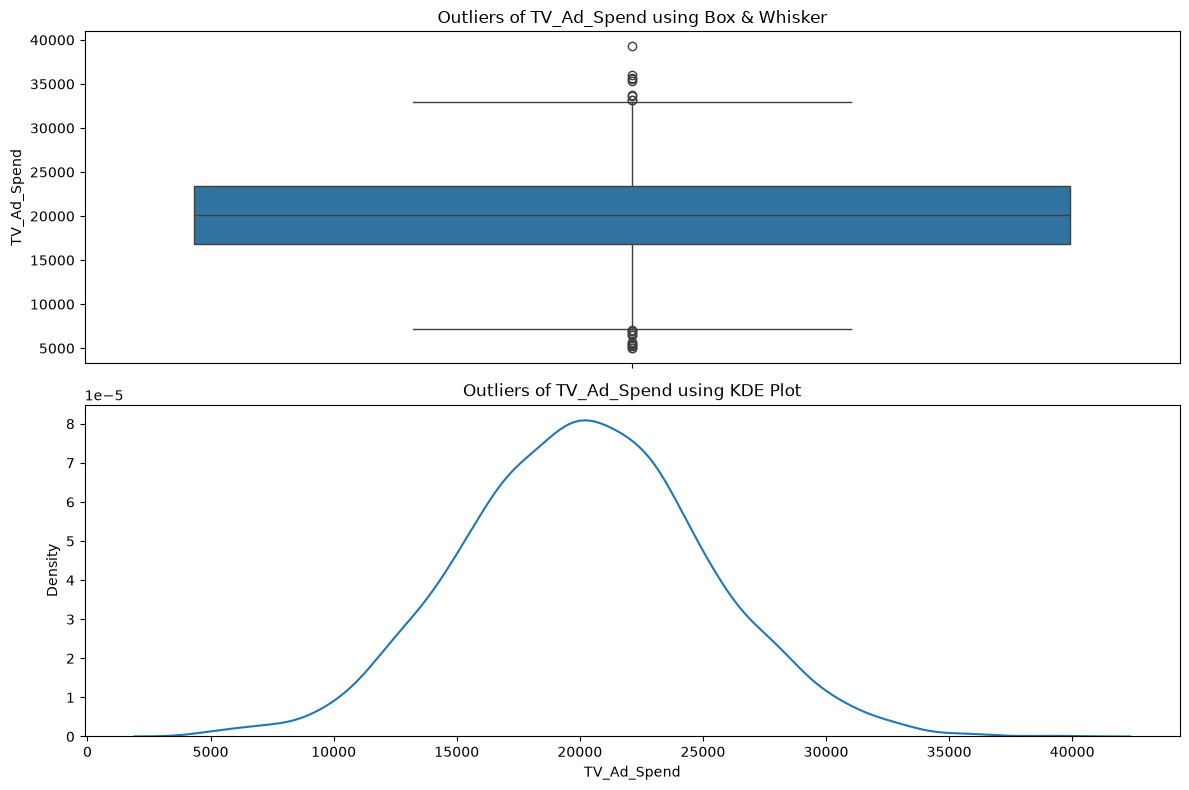

----------------------------------------------------------------------
 
Columns is Social_Media_Spend
__________________________________________________
Minimum value of Social_Media_Spend is 3000.0
Quartile 1 of Social_Media_Spend is 12215.75
Median value of Social_Media_Spend is 15007.5
Average value of Social_Media_Spend is 14921.00981228669
Quartile 3 of Social_Media_Spend is 17555.75
Maximum value of Social_Media_Spend is 30000.0
Lower Outliers value of Social_Media_Spend is 4205.75
Upper Outliers value of Social_Media_Spend is 25565.75
Lower Outliers count is 13
Upper Outliers count is 11
Total Outliers count is 24
--------------------------------------------------------------------------------
 


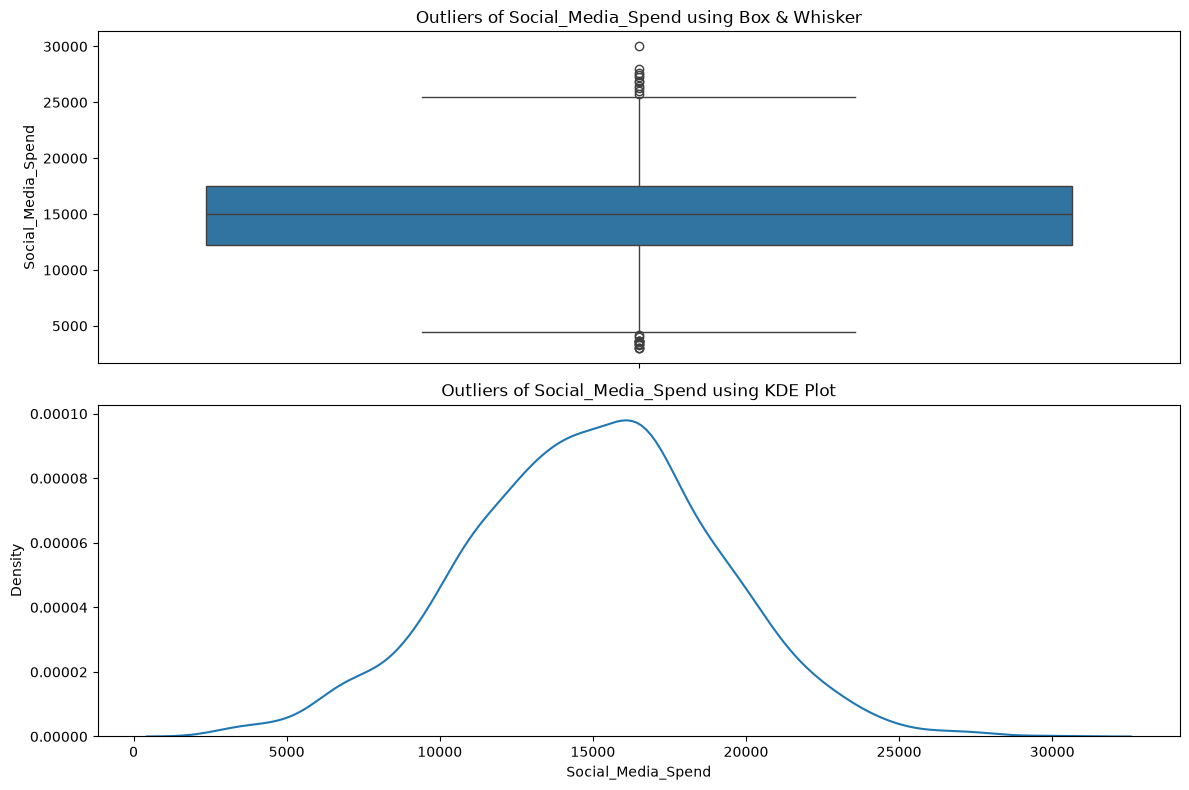

----------------------------------------------------------------------
 
Columns is Discount_Offers
__________________________________________________
Minimum value of Discount_Offers is 0.0
Quartile 1 of Discount_Offers is 10.0
Median value of Discount_Offers is 15.0
Average value of Discount_Offers is 14.309749784296807
Quartile 3 of Discount_Offers is 20.0
Maximum value of Discount_Offers is 30.0
Lower Outliers value of Discount_Offers is -5.0
Upper Outliers value of Discount_Offers is 35.0
Lower Outliers count is 0
Upper Outliers count is 0
Total Outliers count is 0
--------------------------------------------------------------------------------
 


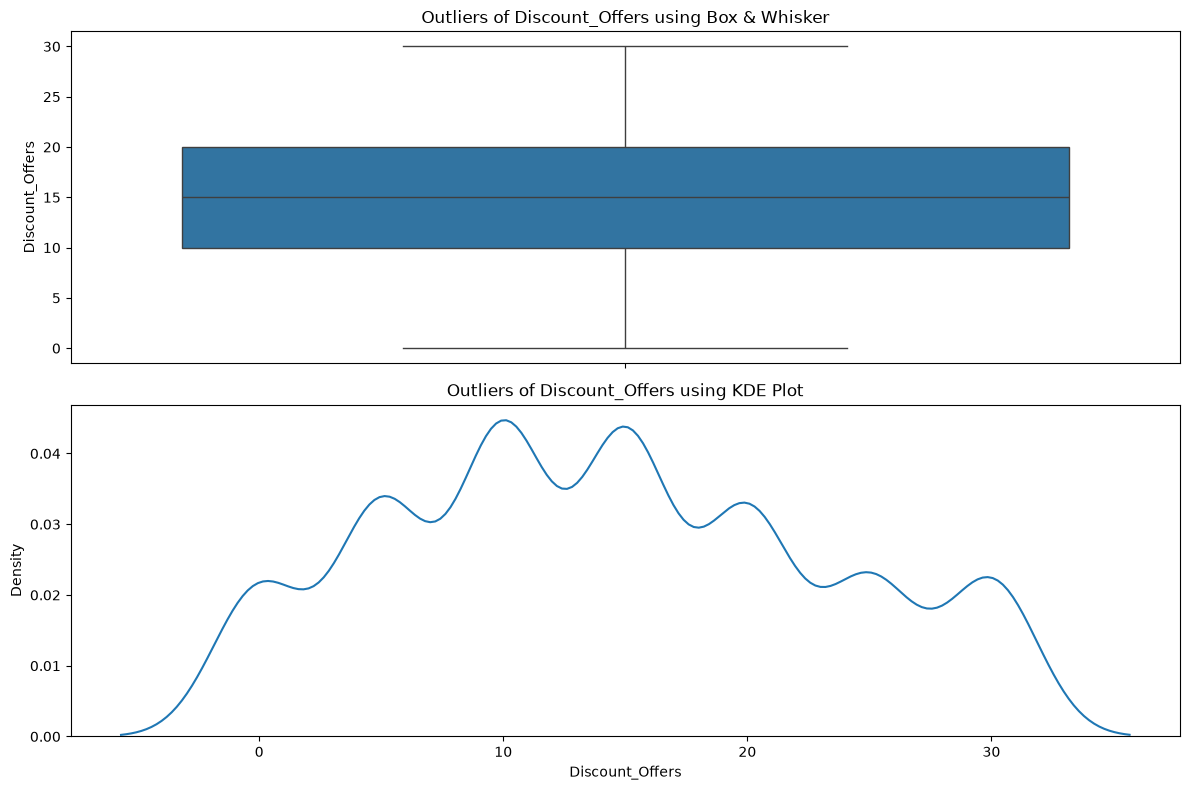

----------------------------------------------------------------------
 
Columns is Search_Engine_Marketing_Spend
__________________________________________________
Minimum value of Search_Engine_Marketing_Spend is 2000
Quartile 1 of Search_Engine_Marketing_Spend is 9479.75
Median value of Search_Engine_Marketing_Spend is 11856.5
Average value of Search_Engine_Marketing_Spend is 11900.0404
Quartile 3 of Search_Engine_Marketing_Spend is 14394.25
Maximum value of Search_Engine_Marketing_Spend is 24351
Lower Outliers value of Search_Engine_Marketing_Spend is 2108.0
Upper Outliers value of Search_Engine_Marketing_Spend is 21766.0
Lower Outliers count is 5
Upper Outliers count is 10
Total Outliers count is 15
--------------------------------------------------------------------------------
 


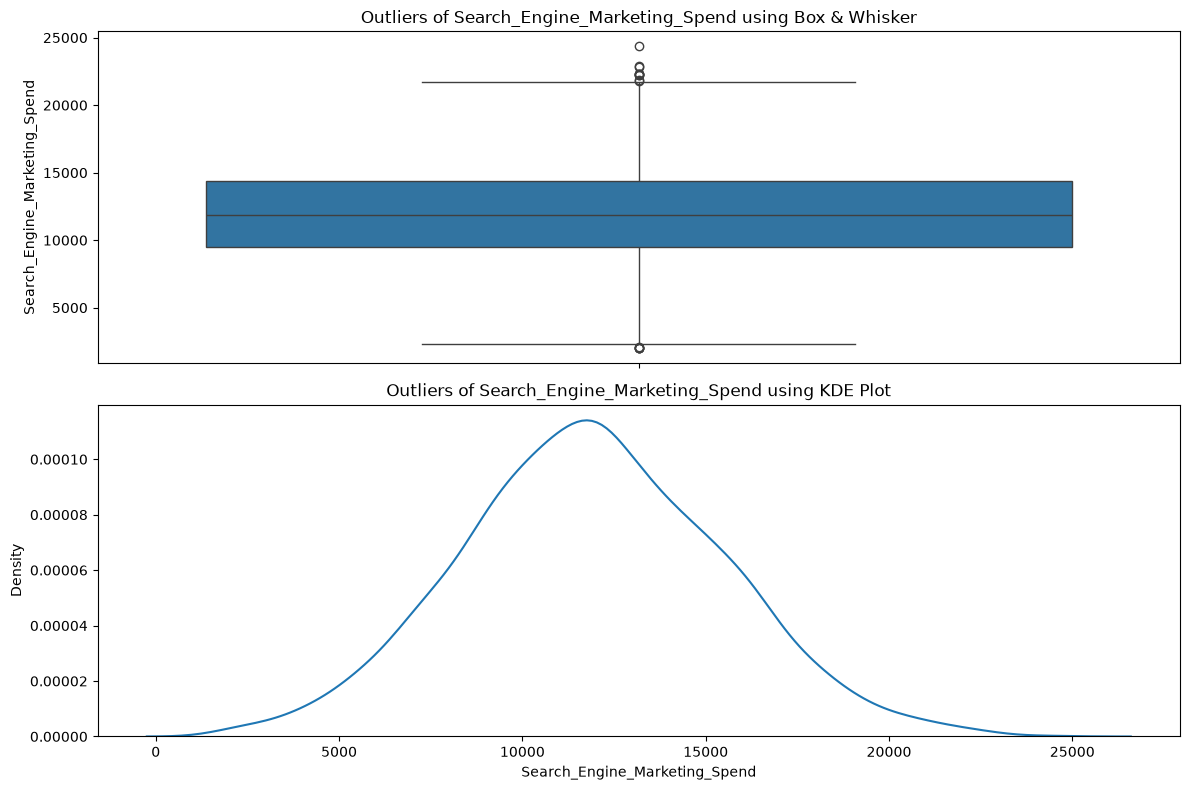

----------------------------------------------------------------------
 
Columns is Website_Traffic
__________________________________________________
Minimum value of Website_Traffic is 1000
Quartile 1 of Website_Traffic is 1000.0
Median value of Website_Traffic is 1000.0
Average value of Website_Traffic is 1175.94
Quartile 3 of Website_Traffic is 1279.0
Maximum value of Website_Traffic is 2542
Lower Outliers value of Website_Traffic is 581.5
Upper Outliers value of Website_Traffic is 1697.5
Lower Outliers count is 0
Upper Outliers count is 191
Total Outliers count is 191
--------------------------------------------------------------------------------
 


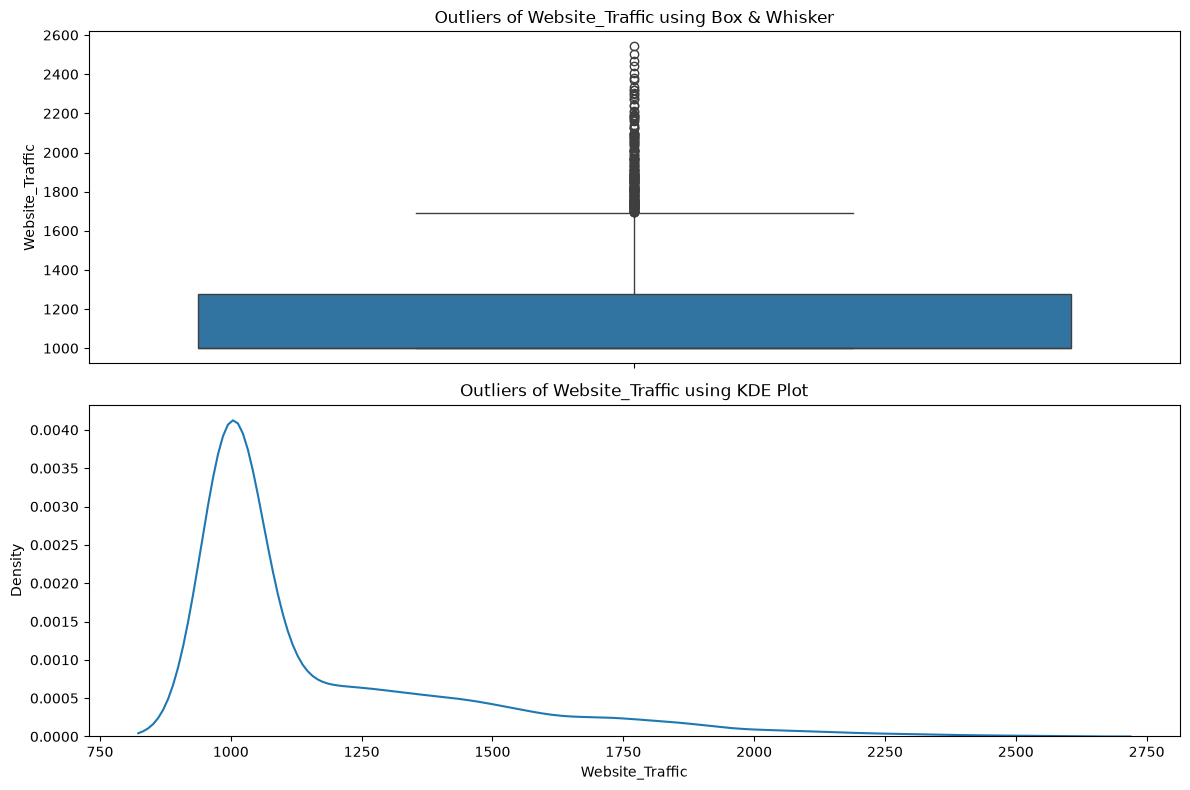

----------------------------------------------------------------------
 
Columns is Conversion_Rate
__________________________________________________
Minimum value of Conversion_Rate is 0.5
Quartile 1 of Conversion_Rate is 1.67
Median value of Conversion_Rate is 2.09
Average value of Conversion_Rate is 2.1360040000000002
Quartile 3 of Conversion_Rate is 2.54
Maximum value of Conversion_Rate is 4.75
Lower Outliers value of Conversion_Rate is 0.36499999999999977
Upper Outliers value of Conversion_Rate is 3.845
Lower Outliers count is 0
Upper Outliers count is 23
Total Outliers count is 23
--------------------------------------------------------------------------------
 


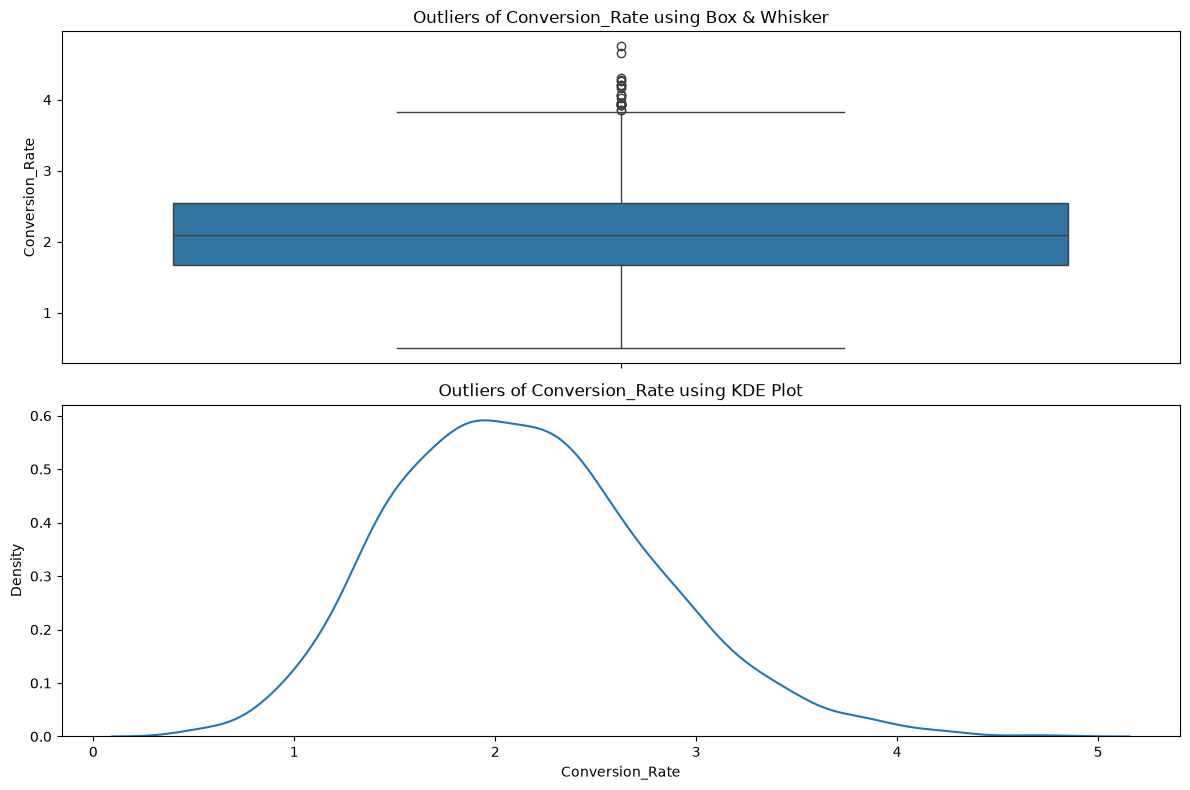

----------------------------------------------------------------------
 
Columns is Sales
__________________________________________________
Minimum value of Sales is 18747
Quartile 1 of Sales is 63358.75
Median value of Sales is 81320.5
Average value of Sales is 83898.0092
Quartile 3 of Sales is 101064.0
Maximum value of Sales is 221038
Lower Outliers value of Sales is 6800.875
Upper Outliers value of Sales is 157621.875
Lower Outliers count is 0
Upper Outliers count is 33
Total Outliers count is 33
--------------------------------------------------------------------------------
 


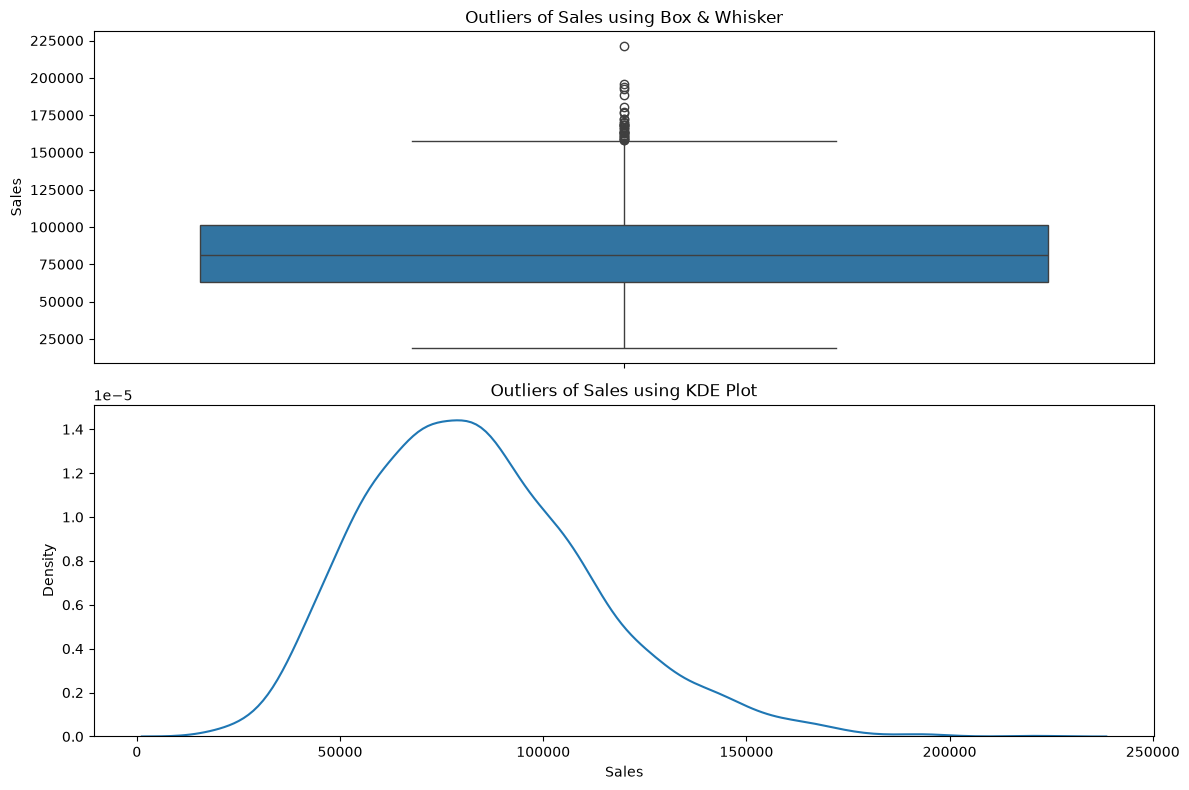

----------------------------------------------------------------------
 


In [22]:
# Outliers

number_cols=market_df.select_dtypes(include='number').columns

for col in number_cols:
    Min=market_df[col].min()
    Q1=market_df[col].quantile(0.25)
    Q2=market_df[col].quantile(0.50)
    Mean=market_df[col].mean()
    Q3=market_df[col].quantile(0.75)
    Max=market_df[col].max()

    IQR=Q3-Q1

    lower_out_value= Q1-1.5*IQR
    upper_out_value= Q3+1.5*IQR


    Lower_Outliers=(market_df[col] < lower_out_value).sum()
    Upper_Outliers=(market_df[col] > upper_out_value).sum()
    total_outliers=Lower_Outliers+Upper_Outliers

    print(f'Columns is {col}')
    print('_'*50)
    print(f'Minimum value of {col} is {Min}')
    print(f'Quartile 1 of {col} is {Q1}')
    print(f'Median value of {col} is {Q2}')
    print(f'Average value of {col} is {Mean}')
    print(f'Quartile 3 of {col} is {Q3}')
    print(f'Maximum value of {col} is {Max}')
    print(f'Lower Outliers value of {col} is {lower_out_value}')
    print(f'Upper Outliers value of {col} is {upper_out_value}')
    print(f'Lower Outliers count is {Lower_Outliers}')
    print(f'Upper Outliers count is {Upper_Outliers}')
    print(f'Total Outliers count is {total_outliers}')
    print('-'*80)
    print(' ')


    # Visualize as well 

    fig,axes=plt.subplots(2,1,figsize=(12,8))

    # plot Box & Whisker plot
    sns.boxplot(market_df[col],ax=axes[0])
    axes[0].set_title(f'Outliers of {col} using Box & Whisker')

    # Plot KDE

    sns.kdeplot(market_df[col],ax=axes[1])
    axes[1].set_title(f'Outliers of {col} using KDE Plot')


    plt.tight_layout()
    plt.show()

    print('-'*70)
    print(' ')

    

### 4. Split the Dataset

In [23]:
X=market_df.drop('Sales',axis=1)
y=market_df['Sales']

print(X.shape)
print(y.shape)

(2500, 9)
(2500,)


In [24]:
# split into train and test

from sklearn.model_selection import train_test_split as tts

X_train,X_test,y_train,y_test=tts(X,y,test_size=0.2,random_state=42)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(2000, 9)
(2000,)
(500, 9)
(500,)


In [25]:
X_train[:1]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate
2055,15903.0,13798.0,20.0,5958,Sports,North,Mid-tier,1000,1.14


In [26]:
X_test[:1]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate
1447,22931.0,16712.0,20.0,10385,Sports,South,Mid-tier,1000,3.06


### 5.Transformation


### a. Missing Values

In [27]:

num_cols=X_train.select_dtypes(include='number').columns
cat_cols=X_test.select_dtypes(include='str').columns

In [28]:
## Transforming with Median value for numerical columns of Train dataset 

for col in num_cols:
    X_train[col]= X_train[col].fillna(X_train[col].median())

In [29]:
## Transforming with Median value for numerical columns of Test dataset 

for col in num_cols:
    X_test[col]= X_test[col].fillna(X_train[col].median())

In [30]:
## Transforming with Mode value for categorical columns of Train dataset 

for col in cat_cols:
   X_train[col]=   X_train[col].fillna(X_train[col].mode()[0])

In [31]:
## Transforming with Mode value for categorical columns of Test dataset 

for col in cat_cols:
     X_test[col]=   X_test[col].fillna(X_train[col].mode()[0])

In [32]:
X_train.isna().sum()

TV_Ad_Spend                      0
Social_Media_Spend               0
Discount_Offers                  0
Search_Engine_Marketing_Spend    0
Product_Category                 0
Region                           0
Customer_Segment                 0
Website_Traffic                  0
Conversion_Rate                  0
dtype: int64

## b.Outliers and Skewness Treatment

In [33]:
for col in num_cols:
    print(f'Skewness value of {col} is {X_train[col].skew()}')
    

Skewness value of TV_Ad_Spend is 0.04405797211560788
Skewness value of Social_Media_Spend is -0.06368656920945912
Skewness value of Discount_Offers is 0.13613613143701309
Skewness value of Search_Engine_Marketing_Spend is 0.13408013168045632
Skewness value of Website_Traffic is 1.8513189578181586
Skewness value of Conversion_Rate is 0.4106301617267023


In [34]:
for col in num_cols:
    print(f'Skewness value of {col} is { np.log1p(X_train[col].skew())}')

Skewness value of TV_Ad_Spend is 0.04311501676514536
Skewness value of Social_Media_Spend is -0.06580499660259045
Skewness value of Discount_Offers is 0.1276331471308932
Skewness value of Search_Engine_Marketing_Spend is 0.12582186566660347
Skewness value of Website_Traffic is 1.0477816794421673
Skewness value of Conversion_Rate is 0.3440365277600723


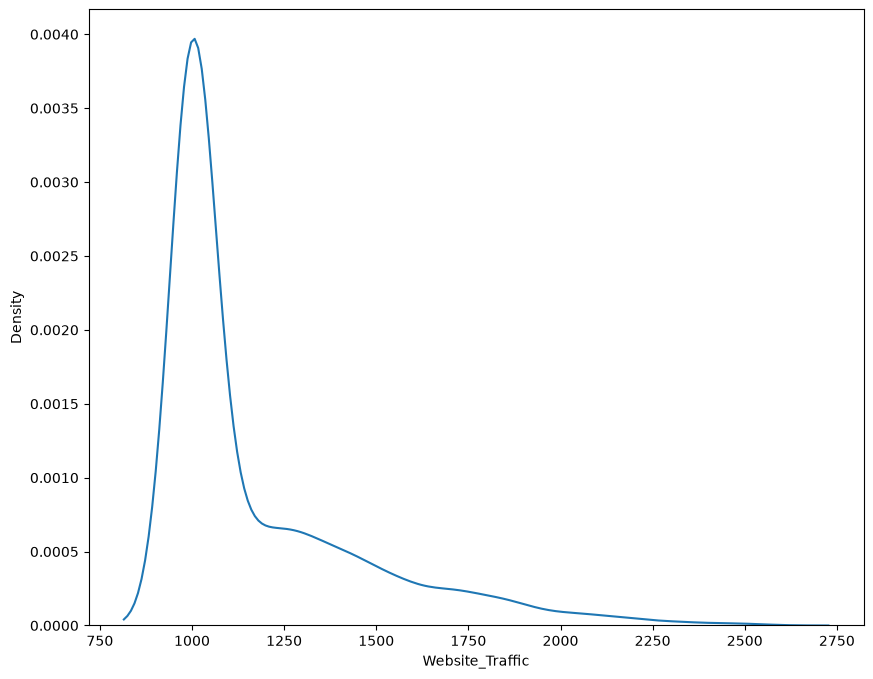

In [35]:
plt.figure(figsize=(10,8))
sns.kdeplot(X_train['Website_Traffic'])
plt.show()

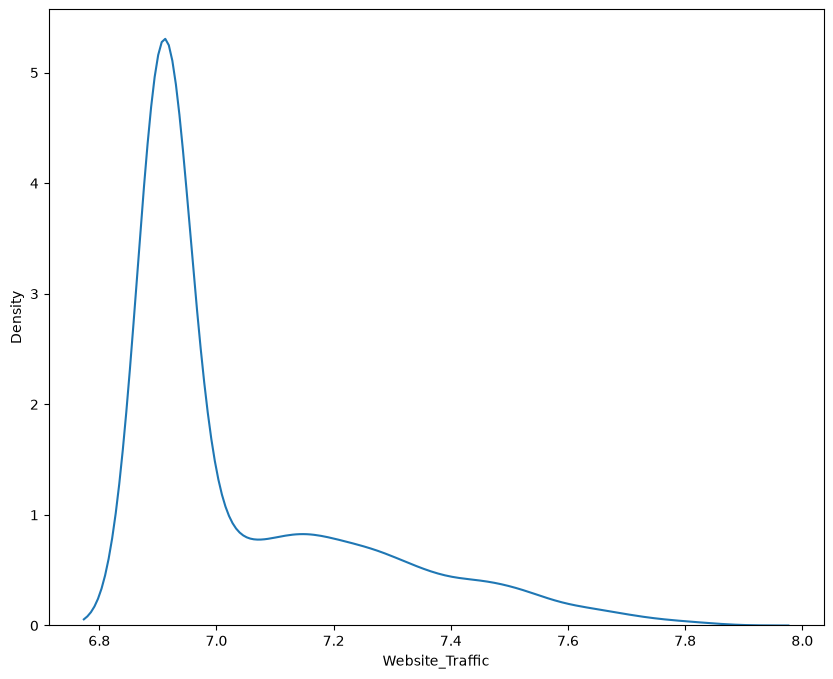

In [36]:
plt.figure(figsize=(10,8))
sns.kdeplot(np.log1p(X_train['Website_Traffic']))
plt.show()

In [37]:
from sklearn.preprocessing import PowerTransformer 

In [38]:
pt =PowerTransformer()
pt

,"method method: {'yeo-johnson', 'box-cox'}, default='yeo-johnson'The power transform method. Available methods are:- 'yeo-johnson' [1]_, works with positive and negative values- 'box-cox' [2]_, only works with strictly positive values",'yeo-johnson'
,"standardize standardize: bool, default=TrueSet to True to apply zero-mean, unit-variance normalization to thetransformed output.",True
,"copy copy: bool, default=TrueSet to False to perform inplace computation during transformation.",True


In [39]:
pt.fit_transform(X_train[['Website_Traffic']])

array([[-5.55111512e-17],
       [ 2.77555756e-17],
       [ 2.77555756e-17],
       ...,
       [ 2.77555756e-17],
       [-5.55111512e-17],
       [-5.55111512e-17]], shape=(2000, 1))

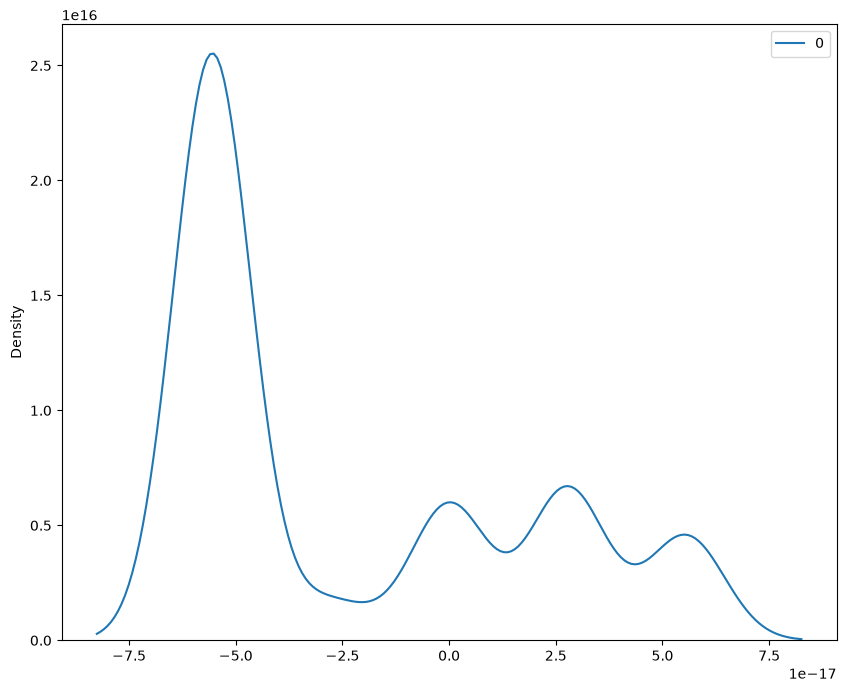

In [40]:
plt.figure(figsize=(10,8))
sns.kdeplot(pt.fit_transform(X_train[['Website_Traffic']]))
plt.show()

In [41]:
pt1 =PowerTransformer(method='box-cox')
pt1

,"method method: {'yeo-johnson', 'box-cox'}, default='yeo-johnson'The power transform method. Available methods are:- 'yeo-johnson' [1]_, works with positive and negative values- 'box-cox' [2]_, only works with strictly positive values",'box-cox'
,"standardize standardize: bool, default=TrueSet to True to apply zero-mean, unit-variance normalization to thetransformed output.",True
,"copy copy: bool, default=TrueSet to False to perform inplace computation during transformation.",True


In [42]:
pt1.fit_transform(X_train[['Website_Traffic']])

array([[0.00000000e+00],
       [8.32667268e-17],
       [8.32667268e-17],
       ...,
       [8.32667268e-17],
       [0.00000000e+00],
       [0.00000000e+00]], shape=(2000, 1))

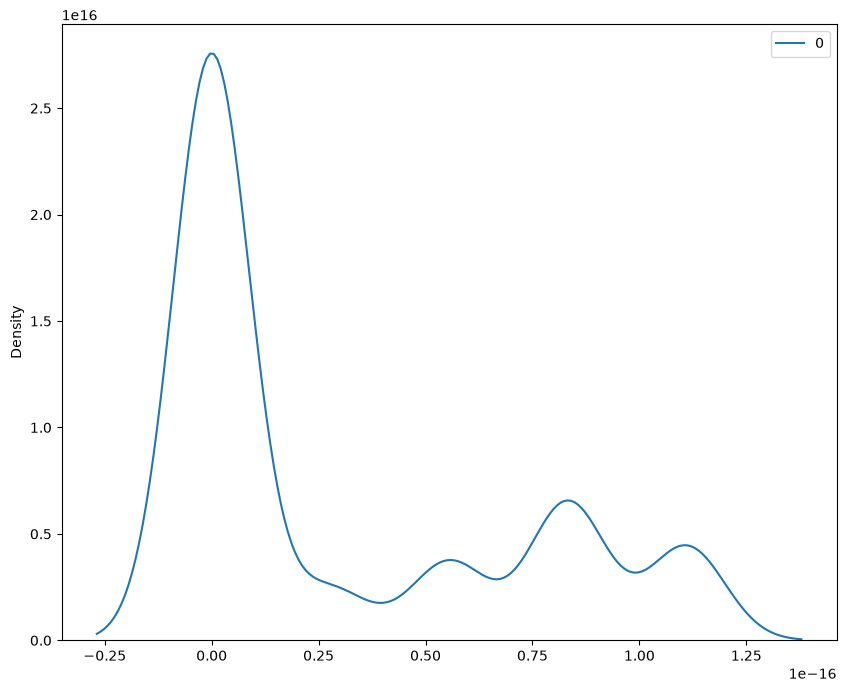

In [43]:
plt.figure(figsize=(10,8))
sns.kdeplot(pt1.fit_transform(X_train[['Website_Traffic']]))
plt.show()

In [44]:
### IQR Technique for Outliers Treatment in training dataset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1

    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR

    total_outliers = ((X_train[col]  < lower_out_value) | (X_train[col] > upper_out_value)).sum()
    
    print(f'Total Outliers count in {col} is {total_outliers}')

Total Outliers count in TV_Ad_Spend is 23
Total Outliers count in Social_Media_Spend is 34
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 11
Total Outliers count in Website_Traffic is 150
Total Outliers count in Conversion_Rate is 16


In [45]:
### IQR Technique for Outliers Treatment in t\sting dataset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1

    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR

    total_outliers = ((X_test[col]  < lower_out_value) | (X_test[col] > upper_out_value)).sum()
    print(f'Total Outliers count in {col} is {total_outliers}')


Total Outliers count in TV_Ad_Spend is 10
Total Outliers count in Social_Media_Spend is 6
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 3
Total Outliers count in Website_Traffic is 41
Total Outliers count in Conversion_Rate is 5


In [46]:
### Treatment

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1

    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR

    total_outliers = ((X_train[col]  < lower_out_value) | (X_train[col] > upper_out_value)).sum()
    
    if total_outliers >0 :
        X_train[col] =X_train[col].clip(lower_out_value,upper_out_value)
        X_test[col] =X_test[col].clip(lower_out_value,upper_out_value)


In [47]:
### IQR Technique for Outliers Treatment for training dataset

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1

    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR

    total_outliers = ((X_train[col]  < lower_out_value) | (X_train[col] > upper_out_value)).sum()
    
    print(f'Total Outliers count in {col} is {total_outliers}')

Total Outliers count in TV_Ad_Spend is 0
Total Outliers count in Social_Media_Spend is 0
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 0
Total Outliers count in Website_Traffic is 0
Total Outliers count in Conversion_Rate is 0


In [48]:
### IQR Technique for Outliers Treatment for testing dataset
for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3-Q1

    lower_out_value = Q1-1.5*IQR
    upper_out_value = Q3+1.5*IQR

    total_outliers = ((X_test[col]  < lower_out_value) | (X_test[col] > upper_out_value)).sum()
    print(f'Total Outliers count in {col} is {total_outliers}')


Total Outliers count in TV_Ad_Spend is 0
Total Outliers count in Social_Media_Spend is 0
Total Outliers count in Discount_Offers is 0
Total Outliers count in Search_Engine_Marketing_Spend is 0
Total Outliers count in Website_Traffic is 0
Total Outliers count in Conversion_Rate is 0


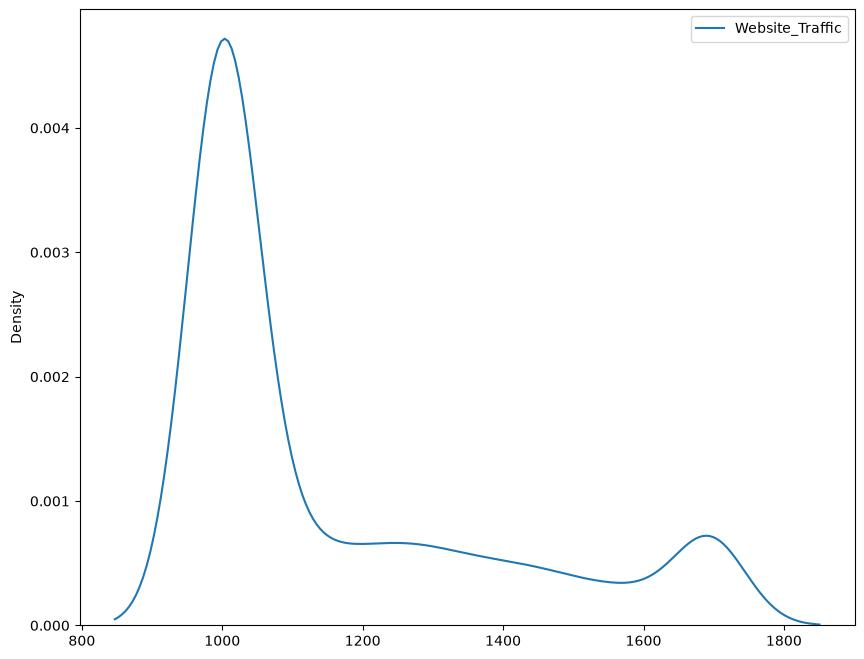

In [49]:
plt.figure(figsize=(10,8))
sns.kdeplot(X_train[['Website_Traffic']])
plt.show()

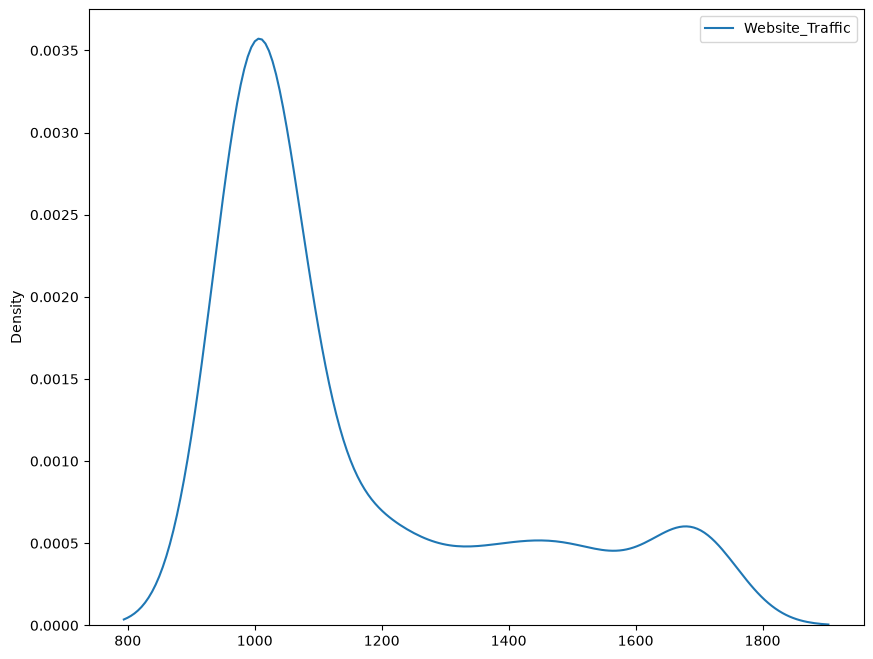

In [50]:
plt.figure(figsize=(10,8))
sns.kdeplot(X_test[['Website_Traffic']])
plt.show()

In [51]:
X_train['Website_Traffic'].skew()

np.float64(1.268857424638329)

In [52]:
X_test['Website_Traffic'].skew()

np.float64(1.2210874622605132)

In [53]:
X_train.shape

(2000, 9)

In [54]:
X_test.shape

(500, 9)

### Concat the training dataset for visualization and Statistical test

In [55]:
train_df=pd.concat([X_train,y_train],axis=1)
train_df[:3]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Product_Category,Region,Customer_Segment,Website_Traffic,Conversion_Rate,Sales
2055,15903.0,13798.0,20.0,5958.0,Sports,North,Mid-tier,1000.0,1.14,42281
1961,21427.0,22397.0,25.0,12812.0,Home Appliances,East,Mid-tier,1549.0,3.06,142404
1864,26521.0,12613.0,20.0,11959.0,FMCG,North,Budget,1474.0,2.09,86869


In [56]:
train_df.dtypes

TV_Ad_Spend                      float64
Social_Media_Spend               float64
Discount_Offers                  float64
Search_Engine_Marketing_Spend    float64
Product_Category                     str
Region                               str
Customer_Segment                     str
Website_Traffic                  float64
Conversion_Rate                  float64
Sales                              int64
dtype: object

In [57]:
train_df['Discount_Offers']=train_df['Discount_Offers'].astype('str')

In [58]:
train_df.dtypes

TV_Ad_Spend                      float64
Social_Media_Spend               float64
Discount_Offers                      str
Search_Engine_Marketing_Spend    float64
Product_Category                     str
Region                               str
Customer_Segment                     str
Website_Traffic                  float64
Conversion_Rate                  float64
Sales                              int64
dtype: object

### Analyse numerical columns with respect to Sales

In [76]:
num_cols1=train_df.select_dtypes(include='number').columns
cat_cols1=train_df.select_dtypes(include='str').columns

In [77]:
num_cols1

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Search_Engine_Marketing_Spend',
       'Website_Traffic', 'Conversion_Rate', 'Sales'],
      dtype='str')

In [78]:
cat_cols1

Index(['Discount_Offers', 'Product_Category', 'Region', 'Customer_Segment'], dtype='str')

In [167]:
train_df['Discount_Offers']=train_df['Discount_Offers'].astype(float)
print(train_df['Discount_Offers'].dtype)

float64


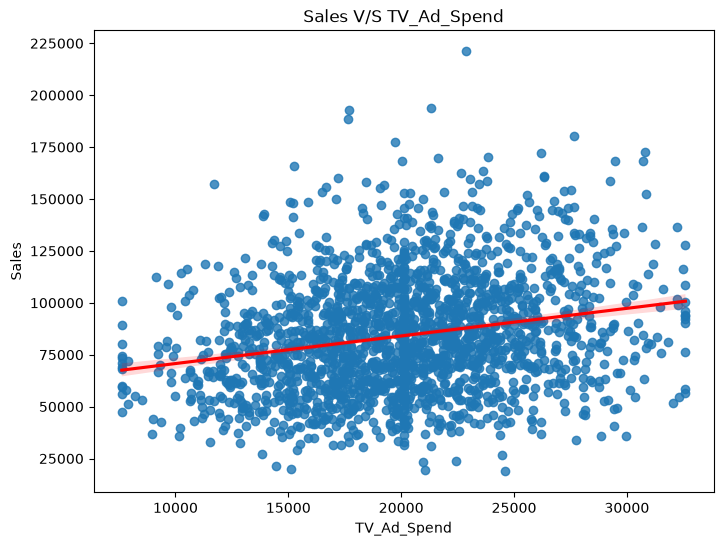

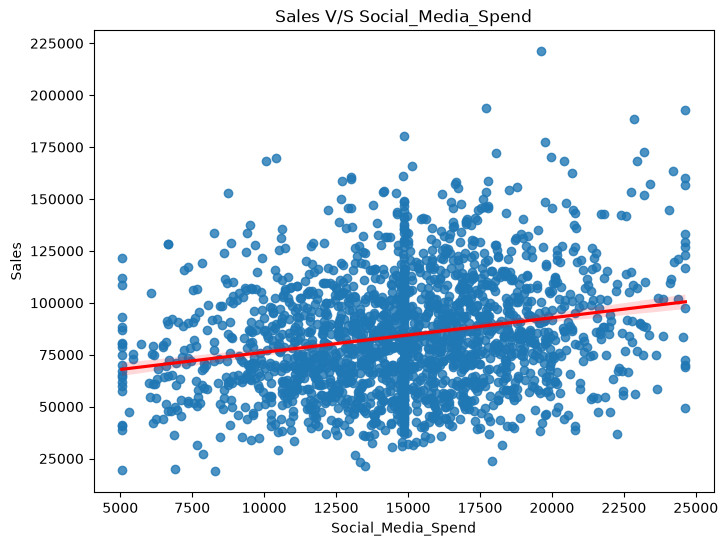

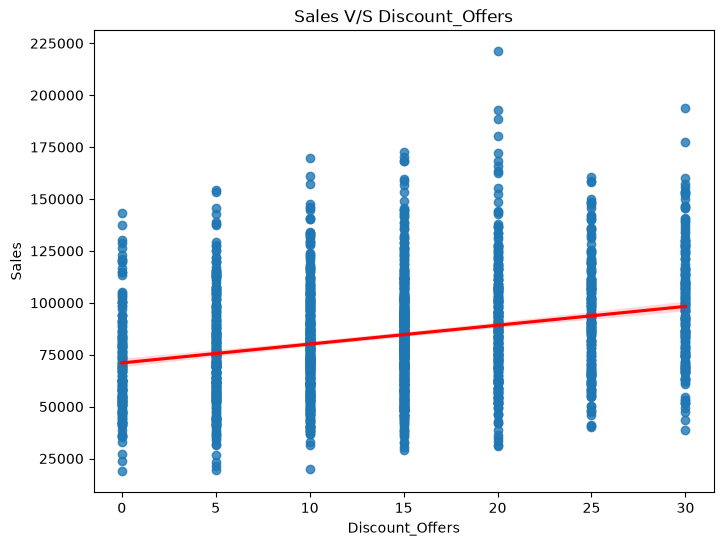

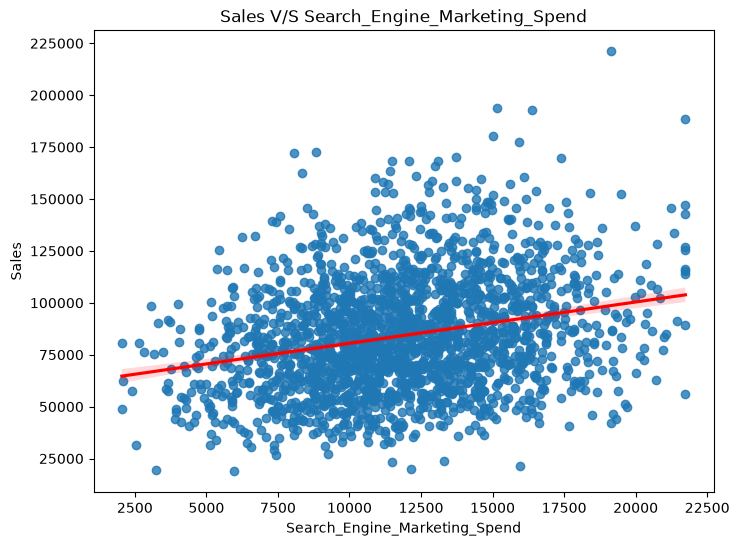

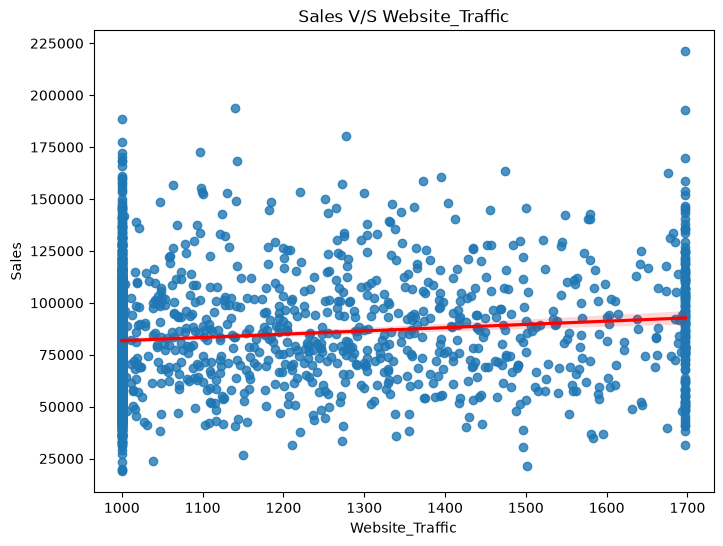

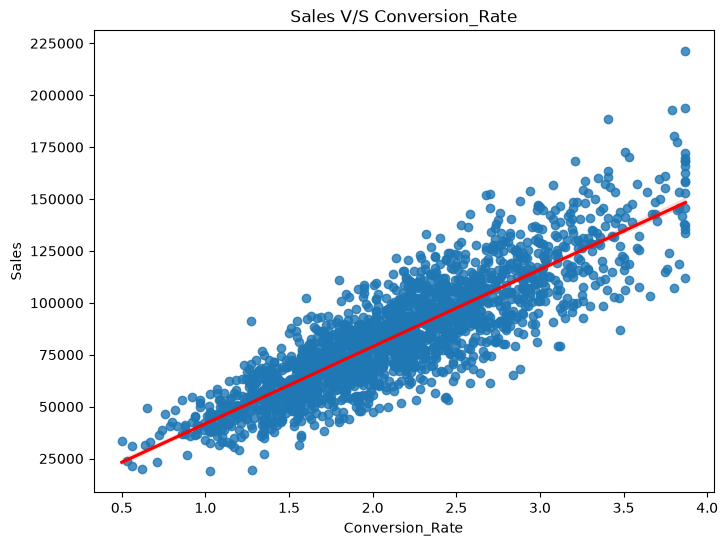

In [168]:
for col in num_cols:
    plt.figure(figsize=(8,6))

    sns.regplot(data=train_df,
                x=col,y='Sales',
                line_kws={'color':'Red'})
    
    plt.title(f'Sales V/S {col}')

    plt.show()
    

### Insights
### Sales and Conversion rates are highly correlated 

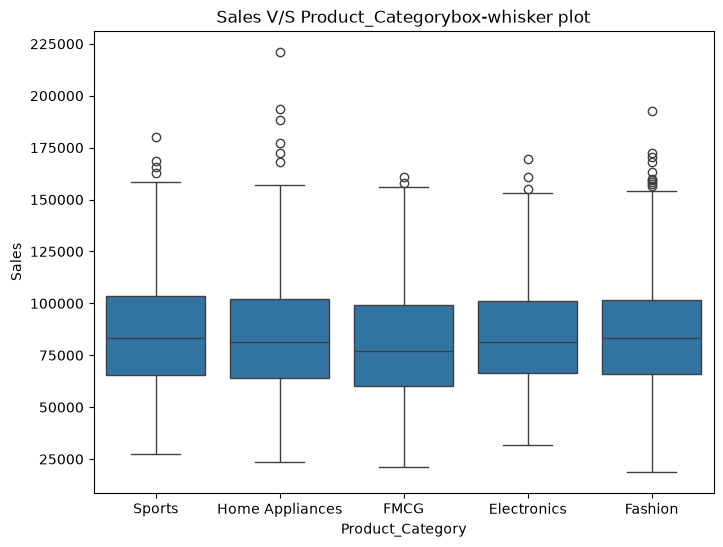

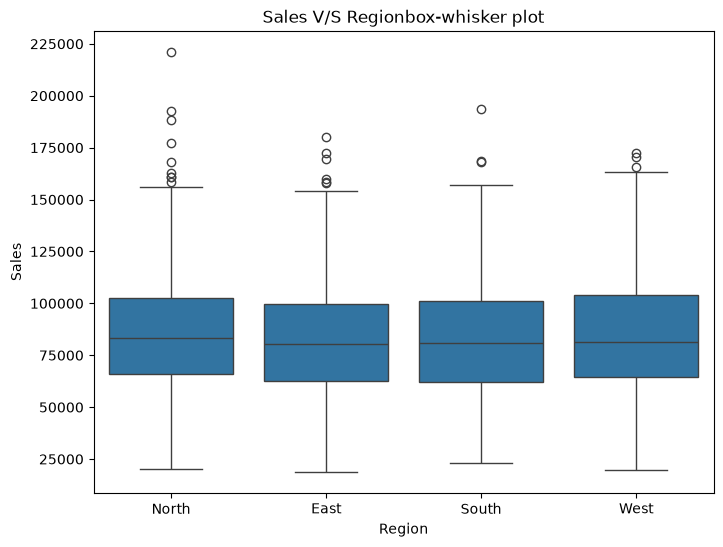

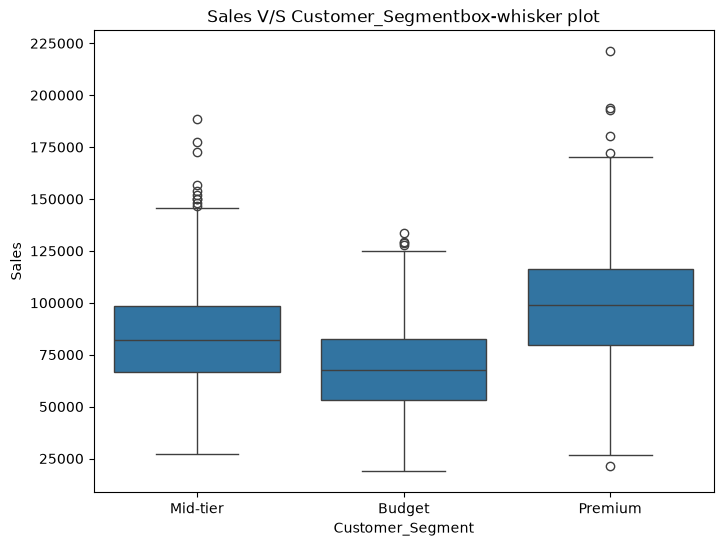

In [101]:
### Analyse Categorical columns and Sales

for col in cat_cols:
    plt.figure(figsize=(8,6))

    sns.boxplot(data=train_df,x=col,y='Sales')
    plt.title(f'Sales V/S {col}box-whisker plot')

    plt.show()


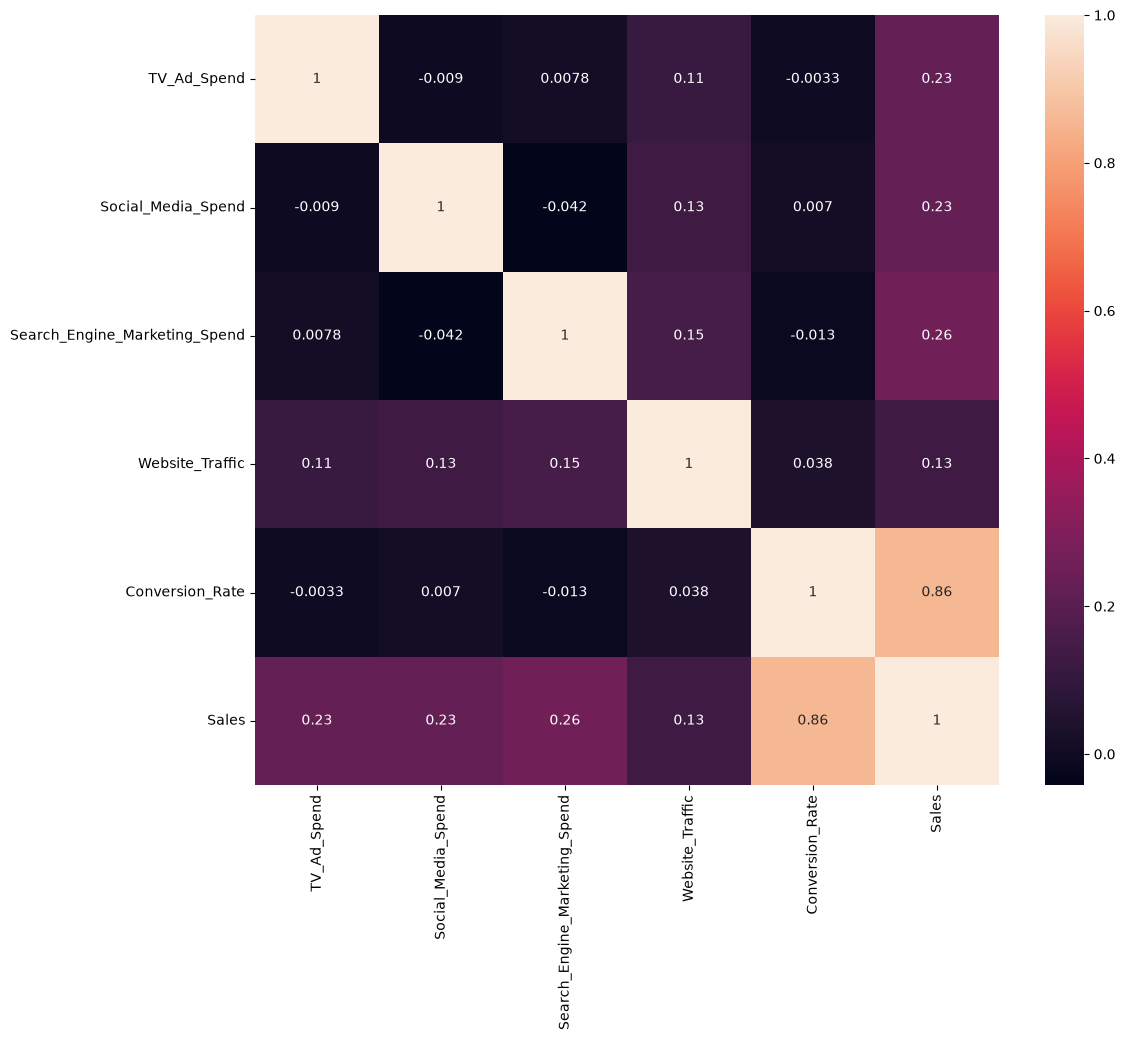

In [102]:
### Heatmap

plt.figure(figsize=(12,10))
corr_matrix=train_df.corr(numeric_only=True)
sns.heatmap(corr_matrix,annot=True)

plt.show()

### Statistical Test

In [103]:
from scipy.stats import f_oneway

In [104]:
train_df.groupby(['Discount_Offers'])

In [105]:
train_df.groupby(['Discount_Offers']).groups

{'0.0': [354, 472, 1972, 2201, 1100, 1566, 2127, 2495, 761, 1351, 1301, 767, 1888, 1710, 1575, 636, 800, 642, 694, 986, 1220, 409, 358, 8, 427, 105, 1552, 1398, 1488, 1811, 63, 677, 377, 2154, 1307, 1029, 32, 2124, 411, 1563, 294, 393, 2342, 1412, 2012, 1383, 2369, 2272, 123, 1652, 1391, 1193, 1189, 250, 2411, 721, 2119, 2033, 726, 710, 1039, 1368, 1171, 1441, 757, 1506, 2393, 26, 1523, 1626, 2398, 1594, 490, 2440, 1287, 2110, 1002, 1393, 243, 1003, 754, 626, 1448, 14, 1277, 288, 549, 2269, 1825, 401, 1372, 2402, 139, 1323, 2248, 1807, 919, 242, 1688, 2116, ...], '10.0': [605, 1014, 1532, 219, 1005, 1505, 1053, 174, 1378, 1263, 2389, 184, 1989, 489, 2277, 1429, 1657, 2185, 2464, 555, 283, 575, 275, 360, 1726, 2102, 1094, 840, 1569, 99, 2196, 2405, 1557, 856, 1135, 2449, 1389, 1407, 1870, 1302, 382, 2290, 1987, 1615, 1550, 788, 500, 1886, 2473, 733, 152, 1000, 561, 685, 1213, 859, 869, 1576, 1087, 1309, 2130, 1749, 2243, 1762, 2131, 937, 1075, 2178, 1730, 447, 1905, 969, 257, 2063, 2118

In [106]:
for name,groups in train_df.groupby(['Region']):
    print(name)
    print('-'*50)
    print(groups)
    
    

('East',)
--------------------------------------------------
      TV_Ad_Spend  Social_Media_Spend Discount_Offers  \
1961      21427.0           22397.000            25.0   
461       20176.0           12565.000             5.0   
266       28162.0           14865.000            25.0   
1560      19893.0           17999.000            15.0   
416       27755.0           14297.000            15.0   
...           ...                 ...             ...   
1482      20137.0           24639.625            20.0   
330       19938.0            8184.000            15.0   
466       23070.0           16410.000            15.0   
1095      19596.0           19585.000            10.0   
1294      20409.0           15031.000            25.0   

      Search_Engine_Marketing_Spend Product_Category Region Customer_Segment  \
1961                        12812.0  Home Appliances   East         Mid-tier   
461                         14308.0      Electronics   East          Premium   
266           

In [107]:
for name,groups in train_df.groupby(['Region']):
    print(name)
    print('-'*50)
    print(groups['Sales'])

('East',)
--------------------------------------------------
1961    142404
461      85361
266      48498
1560     79679
416      83349
         ...  
1482    122854
330      91517
466     131122
1095     38059
1294     94051
Name: Sales, Length: 598, dtype: int64
('North',)
--------------------------------------------------
2055     42281
1864     86869
2326     74297
530      65365
290      89237
         ...  
2047     54344
747      81058
21      129169
2391     64677
1238    118503
Name: Sales, Length: 463, dtype: int64
('South',)
--------------------------------------------------
109     112549
1962     72513
354      85972
1545     95151
2446     85095
         ...  
474     110845
1515     63675
1685     82315
1130     88621
860     115783
Name: Sales, Length: 462, dtype: int64
('West',)
--------------------------------------------------
605     133340
931      87760
2279     57437
1014    122541
2401    107585
         ...  
2433    107154
769     116969
2135     67175
2169   

In [108]:

for col in cat_cols1:
    group=[groups['Sales'].values for name,groups in train_df.groupby(col)]

    f_stat,f_pvalue=f_oneway(*group)

    if f_pvalue <0.05 :
        print('Reject H0: Variance in all groups are different')

    else:
        print('Fail to change :NO change')

Reject H0: Variance in all groups are different
Fail to change :NO change
Fail to change :NO change
Reject H0: Variance in all groups are different


In [109]:
for col in cat_cols1:
    group=[groups['Sales'].values for name,groups in train_df.groupby(col)]

    f_stat,f_pvalue=f_oneway(*group)

    status="Average Sales are not same " if f_pvalue < 0.05 else'Average Sales are Same'
    print(f'Features {col}: F-statsistic = {f_stat:.2f},P-value ={ f_pvalue:.4e} ->{status}')


Features Discount_Offers: F-statsistic = 28.27,P-value =1.4048e-32 ->Average Sales are not same 
Features Product_Category: F-statsistic = 1.55,P-value =1.8409e-01 ->Average Sales are Same
Features Region: F-statsistic = 2.01,P-value =1.0989e-01 ->Average Sales are Same
Features Customer_Segment: F-statsistic = 260.34,P-value =3.3748e-101 ->Average Sales are not same 


### Apply encoding techniques to convert categorical column values to  numerical values


In [110]:
X_train_encoded=X_train.copy()
X_test_encoded=X_test.copy()

In [111]:
cat_cols

Index(['Product_Category', 'Region', 'Customer_Segment'], dtype='str')

In [112]:
num_cols2=X_train_encoded.select_dtypes(include='float64').columns
cat_cols=X_train_encoded.select_dtypes(include='str').columns

In [113]:
X_train_encoded=pd.get_dummies(X_train_encoded,drop_first=True,dtype=int)
X_test_encoded=pd.get_dummies(X_test_encoded,drop_first=True,dtype=int)

In [114]:
X_train_encoded[:3]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Website_Traffic,Conversion_Rate,Product_Category_FMCG,Product_Category_Fashion,Product_Category_Home Appliances,Product_Category_Sports,Region_North,Region_South,Region_West,Customer_Segment_Mid-tier,Customer_Segment_Premium
2055,15903.0,13798.0,20.0,5958.0,1000.0,1.14,0,0,0,1,1,0,0,1,0
1961,21427.0,22397.0,25.0,12812.0,1549.0,3.06,0,0,1,0,0,0,0,1,0
1864,26521.0,12613.0,20.0,11959.0,1474.0,2.09,1,0,0,0,1,0,0,0,0


In [115]:
X_test_encoded[:3]

,TV_Ad_Spend,Social_Media_Spend,Discount_Offers,Search_Engine_Marketing_Spend,Website_Traffic,Conversion_Rate,Product_Category_FMCG,Product_Category_Fashion,Product_Category_Home Appliances,Product_Category_Sports,Region_North,Region_South,Region_West,Customer_Segment_Mid-tier,Customer_Segment_Premium
1447,22931.0,16712.0,20.0,10385.0,1000.0,3.06,0,0,0,1,0,1,0,1,0
1114,20752.0,17771.0,5.0,11275.0,1537.0,2.35,0,0,1,0,0,0,1,1,0
1064,18187.0,18833.0,0.0,12630.0,1090.0,1.38,0,0,0,1,0,0,0,0,0


In [116]:
X_train['Product_Category'].unique()

<ArrowStringArray>
['Sports', 'Home Appliances', 'FMCG', 'Electronics', 'Fashion']
Length: 5, dtype: str

### Scaling Transformation on Numerical columns

In [117]:
from sklearn.preprocessing import StandardScaler

In [118]:
ss=StandardScaler()
ss

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [119]:
X_train_scaled=X_train_encoded.copy()
X_test_scaled=X_test_encoded.copy()

In [120]:
ss.fit_transform(X_train_scaled[num_cols2])

array([[-0.89098189, -0.27177992,  0.6449532 , -1.6634716 , -0.67687864,
        -1.56907265],
       [ 0.27058939,  1.96519653,  1.23341415,  0.26496149,  1.67704935,
         1.43268049],
       [ 1.34174147, -0.58005032,  0.6449532 ,  0.02496245,  1.35547449,
        -0.08383021],
       ...,
       [ 0.30822901,  0.66135585, -1.12042965,  0.33361303,  1.07248861,
         0.10377936],
       [ 0.05652719,  0.04897737,  1.23341415, -1.1364866 , -0.67687864,
         0.65097394],
       [ 0.1837449 , -1.15939054, -1.12042965,  1.26069022, -0.67687864,
         1.10436374]], shape=(2000, 6))

In [121]:
X_train_scaled[num_cols2]=ss.fit_transform(X_train_scaled[num_cols2])
X_test_scaled[num_cols2]=ss.fit_transform(X_test_scaled[num_cols2])

In [122]:
X_train_scaled.shape

(2000, 15)

In [123]:
X_test_scaled.shape

(500, 15)

## Check Assumption of Linear Regression

Linear regression works best when four things hold. We check each one.

| Assumption | Plain-English meaning | Check |
|---|---|---|
| Linearity | Features relate to Sales in a straight-line way | Scatter plots with a line |
| No multicollinearity | Features are not copies of each other | VIF |
| Normal residuals | Prediction errors are roughly bell-shaped | Q-Q plot + Shapiro-Wilk |
| Homoscedasticity | Errors have a similar spread everywhere | Residuals vs Fitted plot |
| Independency | Errors should be Independent  | ACF/PACF & Durbin-Watson Test |

In [124]:
num_cols1

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Search_Engine_Marketing_Spend',
       'Website_Traffic', 'Conversion_Rate', 'Sales'],
      dtype='str')

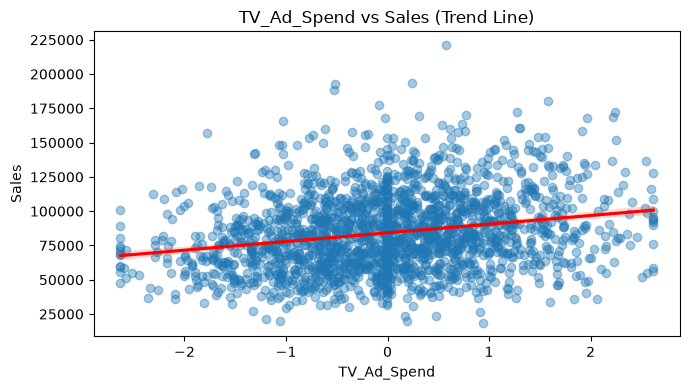

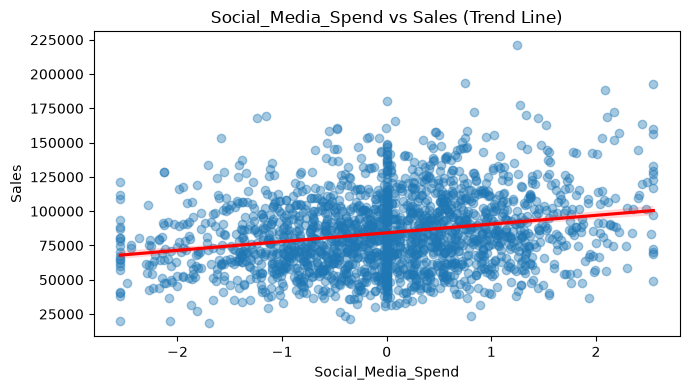

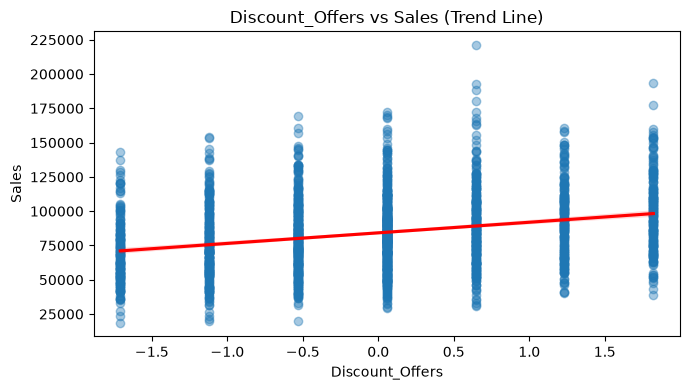

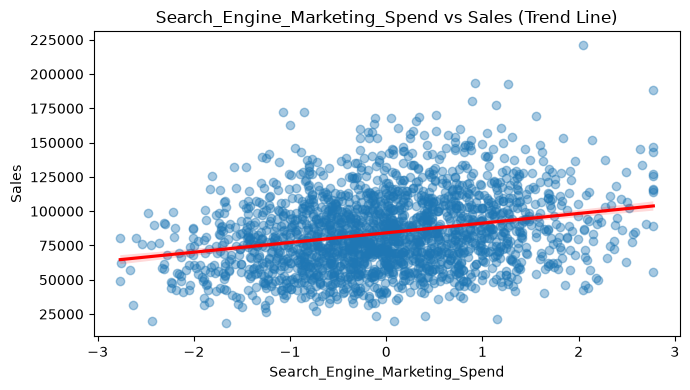

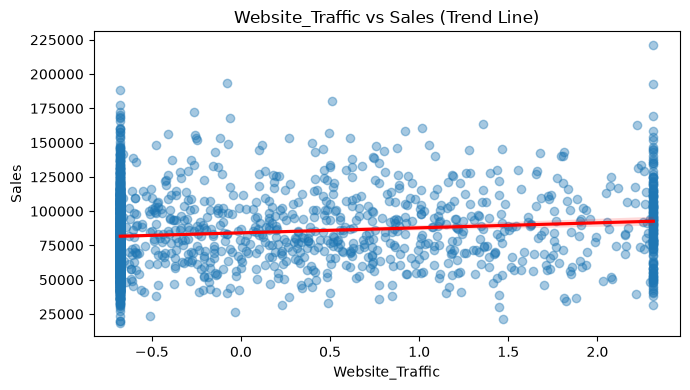

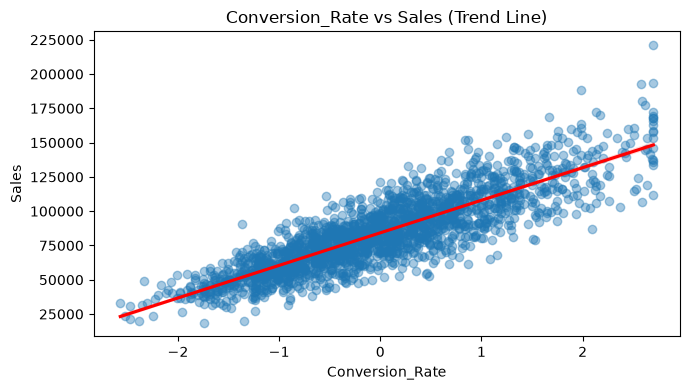

In [125]:
### a. Linear Relationship between X and y

for col in num_cols2:
    plt.figure(figsize=(7, 4))
   
    sns.regplot(data=X_train_scaled, x=col, y=y_train, scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
    plt.title(f'{col} vs Sales (Trend Line)')
    plt.tight_layout()
    plt.show()

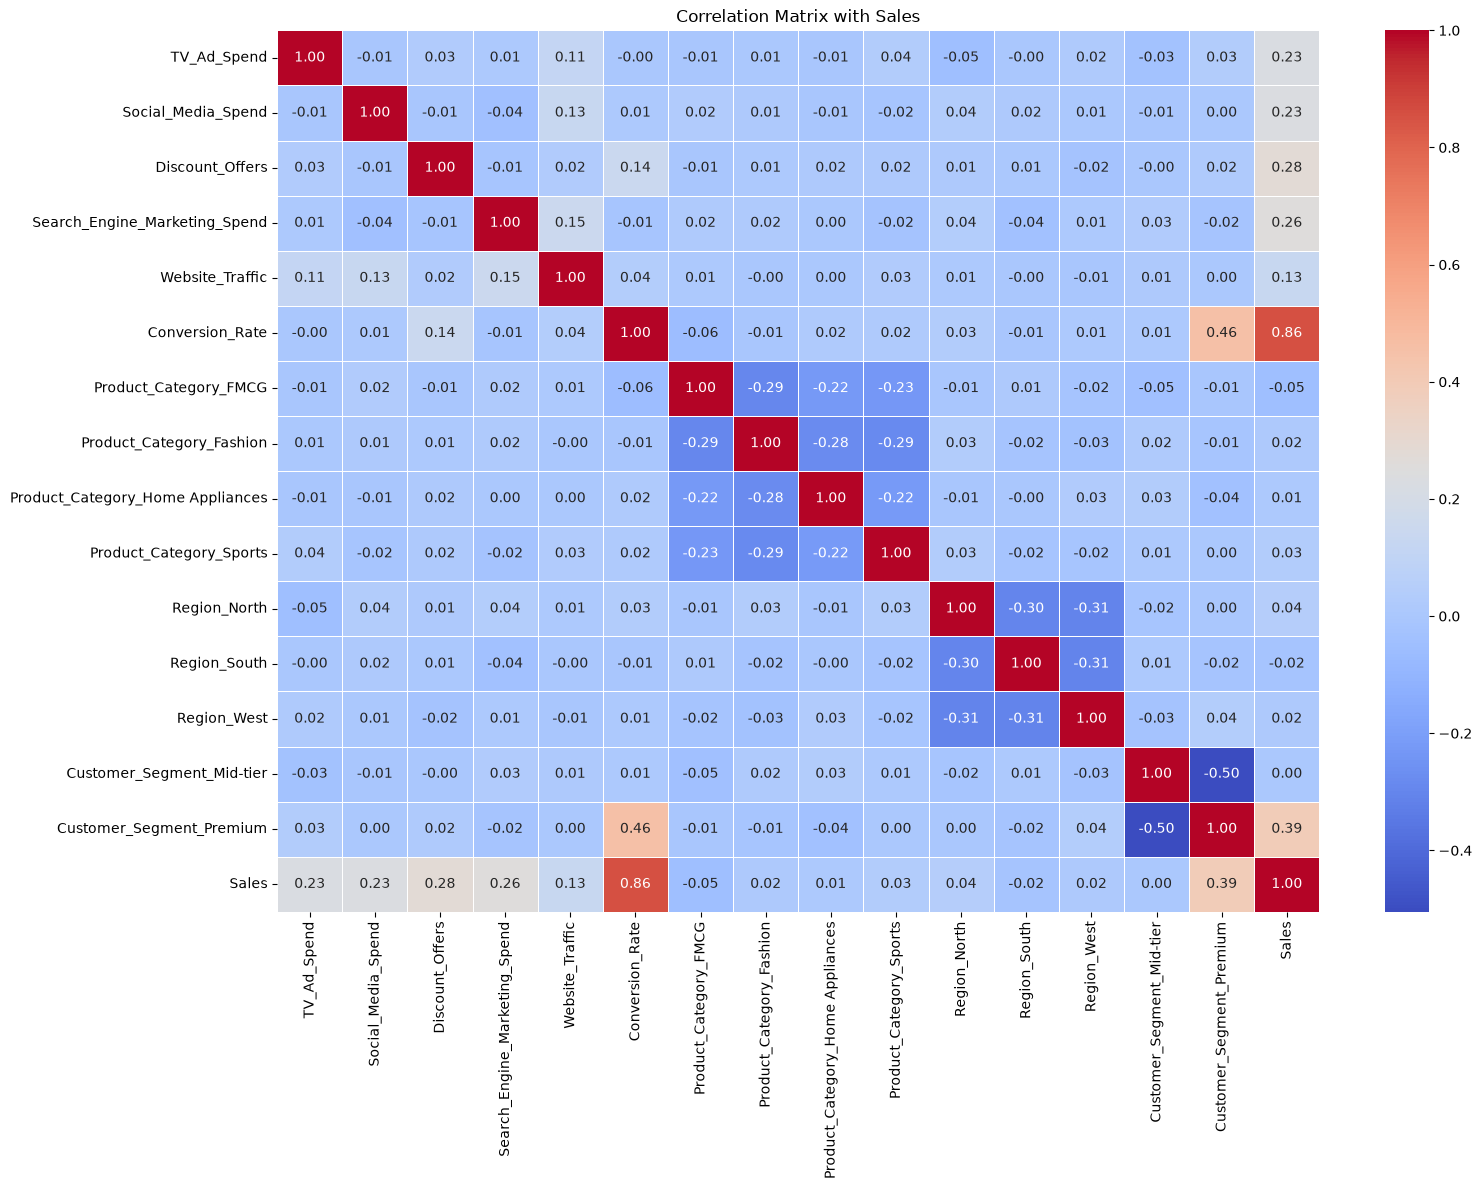

In [126]:
### Heatmap
plt.figure(figsize=(16,12))

corr_matrix = pd.concat([X_train_scaled, y_train], axis=1).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix with Sales')
plt.tight_layout()
plt.show()

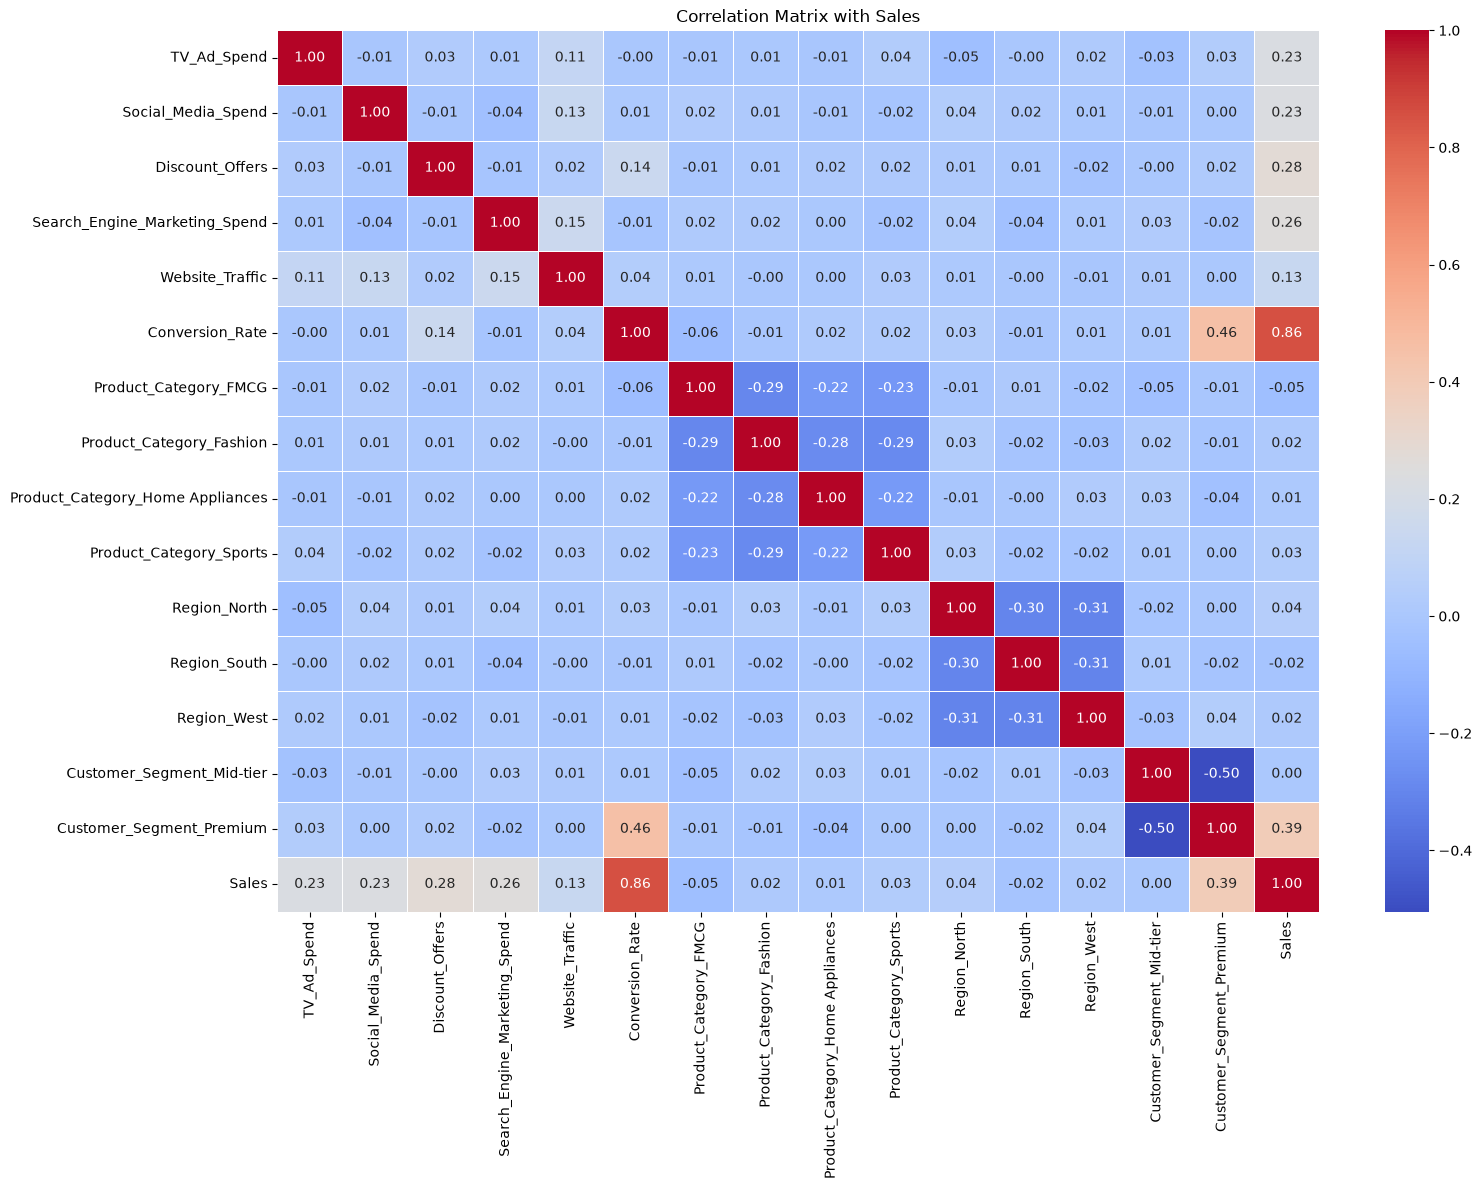

In [127]:
## b. No Multicolinarity

plt.figure(figsize=(16,12))
# Calculate correlation matrix only on numerical fields
corr_matrix = pd.concat([X_train_scaled, y_train], axis=1).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix with Sales')
plt.tight_layout()
plt.show()

In [128]:
## b. No Multicolinarity

import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

X_vif = sm.add_constant(X_train_scaled)

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns
vif_data['VIF Scores'] = [
    vif(X_vif.values,i) for i in range(X_vif.shape[1])
]

vif_data

,Feature,VIF Scores
0,const,11.050084
1,TV_Ad_Spend,1.021568
2,Social_Media_Spend,1.027128
3,Discount_Offers,1.029836
4,Search_Engine_Marketing_Spend,1.033990
5,Website_Traffic,1.063031
6,Conversion_Rate,1.449355
7,Product_Category_FMCG,1.680915
8,Product_Category_Fashion,1.829829
9,Product_Category_Home Appliances,1.634531


## There is no Multicolinearity


## Build the Linear Regression Model

In [129]:
from sklearn.linear_model import LinearRegression

from sklearn.metrics import r2_score,mean_squared_error

In [130]:
model1=LinearRegression()
model1

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [131]:
model1.fit(X_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[6257.95,6628.63,4310.14,..., 535.51,-228.01, 206.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['TV_Ad_Spend','Social_Media_Spend','Discount_Offers',...,'Region_West', 'Customer_Segment_Mid-tier','Customer_Segment_Premium']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8.311e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(15)


In [132]:
print("Coefficient:", model1.coef_)

Coefficient: [ 6257.9474591   6628.62525368  4310.14490944  7646.04614009
   -91.49266775 23143.65483974   443.1391145   1499.82120183
   572.25151254  1548.06990321   544.07265904   -39.6337062
   535.51409108  -228.0142243    206.03009898]


In [133]:
print("Intercept:", model1.intercept_)

Intercept: 83112.58750469283


In [134]:
X_train_scaled.columns

Index(['TV_Ad_Spend', 'Social_Media_Spend', 'Discount_Offers',
       'Search_Engine_Marketing_Spend', 'Website_Traffic', 'Conversion_Rate',
       'Product_Category_FMCG', 'Product_Category_Fashion',
       'Product_Category_Home Appliances', 'Product_Category_Sports',
       'Region_North', 'Region_South', 'Region_West',
       'Customer_Segment_Mid-tier', 'Customer_Segment_Premium'],
      dtype='str')

In [135]:
pred_y_train=model1.predict(X_train_scaled)
pred_y_train

array([ 31408.18549156, 138522.8368313 ,  89557.96308796, ...,
        90682.83718412,  97251.24605052, 107617.84765064], shape=(2000,))

In [136]:
y_train[:10]

2055     42281
1961    142404
1864     86869
2326     74297
461      85361
109     112549
1962     72513
354      85972
266      48498
1545     95151
Name: Sales, dtype: int64

In [137]:
residuals=y_train - pred_y_train
residuals

2055    10872.814508
1961     3881.163169
1864    -2688.963088
2326    -2693.937264
461     -1659.626158
            ...     
1638    -5043.749224
1095   -16892.787632
1130    -2061.837184
1294    -3200.246051
860      8165.152349
Name: Sales, Length: 2000, dtype: float64

In [138]:
residuals.mean()

np.float64(-9.167706593871117e-12)

In [139]:
rmse_train=np.sqrt(mean_squared_error(y_train,pred_y_train))
rmse_train

np.float64(6766.354982053156)

In [140]:
### r2 score

r2_train=r2_score(y_train,pred_y_train)
r2_train

0.9402522311632129

In [141]:
### For Test

pred_y_test=model1.predict(X_test_scaled)
pred_y_test

array([125699.68545165,  92507.06908908,  56632.4953431 ,  97241.52870319,
        87423.58440912,  57604.59251929,  60940.79686278,  60377.88073962,
        82317.54308008,  61372.57822784,  65086.00709112,  81194.13950943,
        54255.82557095, 103269.84146814, 139181.47465842, 144676.01943767,
        81200.16158432,  90538.07595835,  97724.28319663,  57243.60022158,
       131569.38880137,  96117.63781425,  67426.21211361,  42324.76577567,
        67874.49435308, 103204.21348024,  94105.14701519,  92933.26170989,
        84435.8682006 ,  65814.09086983,  69934.25619808,  47832.99414482,
       104075.69697083, 112103.40081602,  95556.54153662, 172300.73736303,
        77660.0590851 ,  75536.08567052,  59165.32848921,  90749.10518695,
        49975.27926017, 106461.70560294, 132902.83403416,  94738.34944991,
        70303.03102611,  81902.19447755, 132533.96413772,  91796.68337122,
       103296.09416597,  93150.76701533,  81009.34415701,  85406.99555698,
        69835.03241116,  

In [142]:
rmse_test=np.sqrt(mean_squared_error(y_test,pred_y_test))
rmse_test

np.float64(6739.9674029947855)

In [143]:
## r2 score

r2_test=r2_score(y_test,pred_y_test)
r2_test

0.9451301296985205

### Checking with other Models

In [144]:
from sklearn.neighbors import KNeighborsRegressor

In [145]:
pre_y_knn_train = KNeighborsRegressor(metric='euclidean').fit(X_train_scaled,y_train).predict(X_train_scaled)
pre_y_knn_train

array([ 44894. , 125402.2,  86415.4, ...,  90702.8, 103727.4, 106376.8],
      shape=(2000,))

In [146]:
r2_score(y_train,pre_y_knn_train)

0.8823515836858569

### Check other assumptions after Model Building

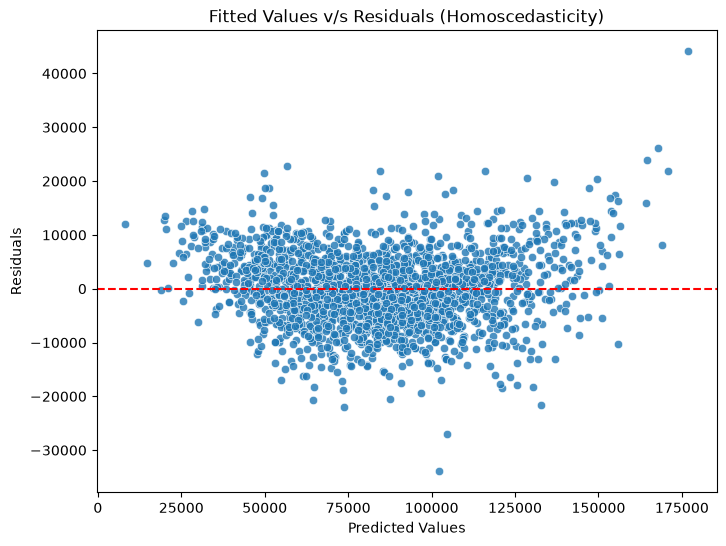

In [147]:
## c. Homoscedasticity

residuals = y_train - pred_y_train

plt.figure(figsize=(8,6))
sns.scatterplot(x=pred_y_train,y=residuals,alpha=0.8)
plt.axhline(0, color="red", linestyle="--") 
plt.title("Fitted Values v/s Residuals (Homoscedasticity)")
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

plt.show()

In [148]:
# Run White's Test

from statsmodels.stats.diagnostic import het_breuschpagan,het_white

lm_stat, lm_pvalue, f_stat, f_pvalue = het_white(residuals, X_vif)

print(f"White's Test LM P-Value: {lm_pvalue:.4e}")
print(f"White's Test LM Stat-Value: {lm_stat:.4e}")

if lm_pvalue < 0.05:
    print("Reject H0: Heteroscedasticity is present.")
else:
    print("Fail to reject H0: Data is homoscedastic (constant variance).")

White's Test LM P-Value: 2.2526e-27
White's Test LM Stat-Value: 3.6389e+02
Reject H0: Heteroscedasticity is present.


In [149]:
# Run the Breusch-Pagan-Godfrey test

lm_stat, lm_pvalue, f_stat, f_pvalue = het_breuschpagan(residuals, X_vif)

print("--- Breusch-Pagan Test Results ---")
print(f"Lagrange Multiplier (LM) Statistic: {lm_stat:.4f}")
print(f"LM P-Value: {lm_pvalue:.4e}")
print(f"F-Statistic: {f_stat:.4f}")
print(f"F-Test P-Value: {f_pvalue:.4e}\n")

# 4. Interpret the Null Hypothesis (H0: Homoscedasticity / Constant Variance)
if lm_pvalue < 0.05:
    print("Reject H0: Heteroscedasticity is present (variance is not constant).")
else:
    print("Fail to reject H0: Data is homoscedastic (variance is constant).")

--- Breusch-Pagan Test Results ---
Lagrange Multiplier (LM) Statistic: 51.0133
LM P-Value: 8.2150e-06
F-Statistic: 3.4620
F-Test P-Value: 7.0170e-06

Reject H0: Heteroscedasticity is present (variance is not constant).


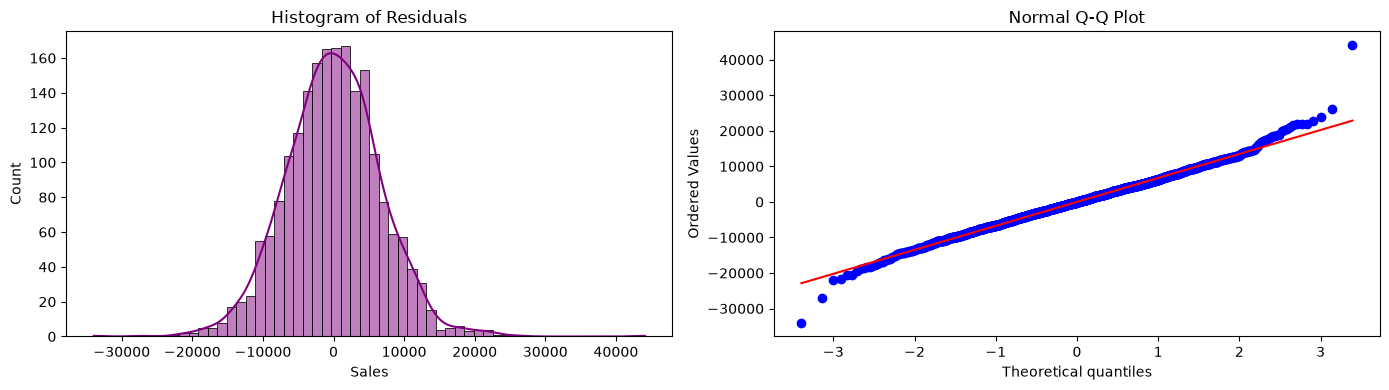

Goal: Residuals should look bell-curved, and Q-Q dots should line up flat against the red line.


In [150]:
## 2. NORMALITY OF RESIDUALS

from scipy.stats import probplot

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(residuals, kde=True, ax=axes[0], color='purple')
axes[0].set_title("Histogram of Residuals")

probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot")
plt.tight_layout()
plt.show()
print("Goal: Residuals should look bell-curved, and Q-Q dots should line up flat against the red line.")


In [151]:
## Run Shapiro test

from scipy.stats import shapiro

sh_stat, sh_p_value = shapiro(residuals)

print(sh_stat)
print(sh_p_value)

if sh_p_value < 0.05:
    print('Reject H0 : Residuals do not follow Normal Distribution curve')

0.9912999993965977
1.4522418703871429e-09
Reject H0 : Residuals do not follow Normal Distribution curve


In [152]:
## 3. INDEPENDENCE OF ERRORS

from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

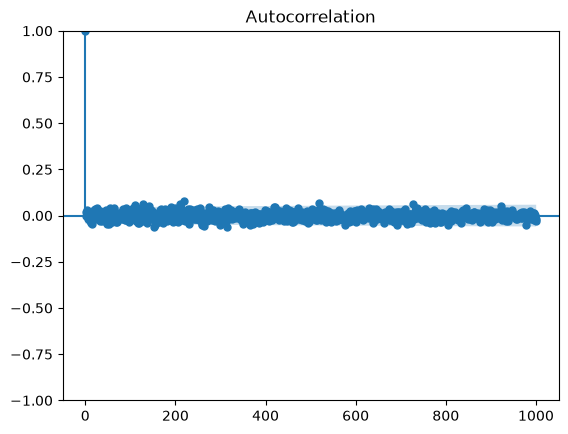

In [153]:
plot_acf(residuals,lags=1000)
plt.show()

In [154]:
## Durbin-Watson test

from statsmodels.stats.stattools import durbin_watson

durbin_watson(residuals)

np.float64(1.9542388704722935)

### Insights: No Autocorrelation

In [155]:
## Check on testing dataset

pred_y_test = model1.predict(X_test_scaled)
pred_y_test[:10]

array([125699.68545165,  92507.06908908,  56632.4953431 ,  97241.52870319,
        87423.58440912,  57604.59251929,  60940.79686278,  60377.88073962,
        82317.54308008,  61372.57822784])

In [156]:
rmse_test = np.sqrt(mean_squared_error(y_test,pred_y_test))
rmse_test

np.float64(6739.9674029947855)

In [157]:
## r2 score for Test Dataset

r2_test = r2_score(y_test,pred_y_test)
r2_test

0.9451301296985205

# 💡 Business Takeaways

1. **Conversion rate is the #1 driver of sales.** A 1-point rise in `Conversion_Rate` is linked to roughly **+35,900 Sales**, and a typical jump (one standard deviation) adds about 23,000, more than any marketing channel. Improving the checkout, landing pages and offers is likely to pay off more than simply buying more traffic.

2. **Every marketing channel helps, and Search looks most efficient.** Per 1 unit of spend, Search Engine Marketing adds about **2.1 Sales**, Social Media about **1.7** and TV about **1.3**. Discounts also help (about +505 Sales per extra discount point). If budget is tight, shifting some money from TV to Search and Social is worth testing.

3. **More visitors alone do not guarantee more sales.** After accounting for conversion rate and spend, `Website_Traffic` has almost no effect (coefficient ≈ 0). Category, region and customer segment matter only a little compared with the average sale of about 84,000.

**Model quality:** the model explains about **95% of the variation in Sales** on unseen test data (R² ≈ 0.95), with an average error of about 6,400 (RMSE). Train and Test scores are very close, so the model is **not overfitting**.

⚠️ **Remember:** regression shows *association*, not proof of cause and effect. Treat these results as strong hints and confirm them with small real-world experiments (A/B tests) before moving big budgets.